# Task 3 – CIGRE-Mittelspannungsnetz

**Ziel:** Das Mittelspannungs-Testnetz CIGRE-MV wird in pandapower aufgebaut, mit einem Lastfluss berechnet und ausgewertet (Busspannungen, Leitungsauslastungen). Anschließend wird es um das Ortsnetz aus Task 2 mit saisonaler Einspeisung erweitert.

**Aufbau des Notebooks:**

1. Daten laden: Lastprofil der Haushalte, Windenergieanlage, PV-Anlage, Wetterdaten
2. Netzaufbau CIGRE-MV: Netzplan und Komponenten
3. Lastfluss, Ergebnisse und Auswertung (statisch und saisonal über 12 typische Wochen)
4. Erweiterung um das Ortsnetz aus Task 2 *(folgt)*

## Importe

In [87]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandapower as pp
import pandapower.networks as pn

# Alle Module liegen im Ordner dieses Notebooks (task3)
TASK3 = Path(".")
import profiles as pr
import weather as wt
from profiles import Lastprofil, Month, DayType, Season

import plots

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# 20 unterscheidbare Farben, damit alle 15 Busse in einem Diagramm unterscheidbar bleiben
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=plt.cm.tab20.colors)

Module im Ordner `task3` (Beschreibung siehe `README.md`):

- `profiles.py`: Einlesen und Aufbereiten der BDEW-Standardlastprofile 2025 (Wochen bilden, Dynamisierung, Skalierung), übernommen aus Task 2 und erweitert
- `weather.py`: Wetterdaten (Open-Meteo) und Umrechnung in PV- und Windleistung über die Kennlinien, übernommen aus Task 2
- `plots.py`: Diagramme mit einheitlicher Zeitachse (Uhrzeit im 6-Stunden-Takt, Tageswechsel als senkrechte Linie, Datum über jedem Tag) Komponentenübersicht des Netzes und `table()` für formatierte Tabellen (farbig, wenn `jinja2` installiert ist)
- `simulation.py`, `elements.py`, `timeseries.py`, `diagrams.py`: Simulationssoftware für die saisonale Lastflussrechnung (Abschnitt 3.2)

In [88]:
def monatstabelle(s, groesse, stat="max", elemente=None):
    """Monatstabelle (Elemente × Monate) einer Simulation, farbig hinterlegt.
    groesse: "Spannung", "Winkel", "Leitung" oder "Trafo"; stat: "max", "min" oder "mean"."""
    art = {  # Ergebnistabelle, Titel, Zahlenformat, Farbskala, Bereich der Farbskala
        "Spannung": ("vm_pu", "U {} [pu]", "{:.3f}",
                     "RdYlGn_r" if stat == "max" else "RdYlGn", (1.0, 1.08) if stat == "max" else (0.92, 1.03)),
        "Winkel":   ("va_degree", "Winkel {} [°]", "{:.2f}", "coolwarm", (None, None)),
        "Leitung":  ("line_loading", "Leitung {} [%]", "{:.1f}", "YlOrRd", (0, 100)),
        "Trafo":    ("trafo_loading", "Trafo {} [%]", "{:.1f}", "YlOrRd", (0, 100)),
    }
    attr, titel, fmt, cmap, (vmin, vmax) = art[groesse]
    df = getattr(s.results, attr)
    if elemente is not None:
        df = df[elemente]
    monat = s.results.info["month"].map(lambda m: Month[m].label)
    t = df.groupby(monat).agg(stat).T[[m.label for m in Month]]
    t.index.name = titel.format(stat)
    return t.style.format(fmt, na_rep="–").background_gradient(cmap=cmap, vmin=vmin, vmax=vmax, axis=None)

## 1 Daten laden

Alle Eingangsdaten werden einmal zu Beginn geladen und stehen danach in Variablen zur Verfügung:

| Variable | Datei | Inhalt |
|---|---|---|
| `PROFILES` | `data/BDEW_H25_Haushalte.csv`, `data/BDEW_G25_Gewerbe.csv` | BDEW-Standardlastprofile H25 (Haushalt) und G25 (Gewerbe), je 12 Monate × 3 Tagtypen × 96 Viertelstunden |
| `WEATHER` | `data/weather_weeks_2025.csv` | je Monat eine typische Woche (stündlich) mit Wetter und berechneter PV- und Windleistung |

Die Wetterdaten wurden in Task 2 einmalig über die Open-Meteo-API abgerufen und als CSV gespeichert; das Notebook benötigt deshalb keinen Internetzugang.

In [89]:
DATA = TASK3 / "data"
WEATHER_FILE = DATA / "weather_weeks_2025.csv"

PROFILES = pr.load_profiles(DATA)
WEATHER = wt.load_weather_weeks(WEATHER_FILE)                  # {Month: DataFrame mit 168 Stunden}
WEEK_STARTS = {m: df.index[0] for m, df in WEATHER.items()}     # Montag jeder Wetterwoche

ANNUAL_KWH = 3500                                               # Jahresverbrauch eines Haushalts [kWh/a]

for profil, df in PROFILES.items():
    print(f"{profil.label}: {df.shape[0]} Viertelstunden × {df.shape[1]} Spalten (Monat, Tagtyp)")
print(f"Wetter:     {len(WEATHER)} Wochen × {len(next(iter(WEATHER.values())))} Stunden")

H25 – Haushalt: 96 Viertelstunden × 36 Spalten (Monat, Tagtyp)
G25 – Gewerbe allgemein: 96 Viertelstunden × 36 Spalten (Monat, Tagtyp)
L25 – Landwirtschaft: 96 Viertelstunden × 36 Spalten (Monat, Tagtyp)
P25 – Haushalt mit PV (Netzbezug): 96 Viertelstunden × 36 Spalten (Monat, Tagtyp)
S25 – Haushalt mit PV und Speicher (Netzbezug): 96 Viertelstunden × 36 Spalten (Monat, Tagtyp)
Wetter:     12 Wochen × 168 Stunden


In [90]:
import simulation as sim
from elements import Diagram, Profile

cigre = sim.loadSimulation("cigre_mv")

## 4 verschiedene Simulationen

### Parellel betrieb und Trafo ausfall simulieren

#### Simulationen durchführen

In [91]:
s1_zu = cigre.copy("s1_zu", overwrite=True)
s1_zu.changeParameter("S1", "closed", True)
s1_zu.runSimulation()

s3_zu = cigre.copy("s3_zu", overwrite=True)
s3_zu.changeParameter("S3", "closed", True)
s3_zu.runSimulation()

Simulation 's1_zu': 2016 Lastflüsse in 86 s, nicht konvergiert: 0
Simulation 's3_zu': 2016 Lastflüsse in 80 s, nicht konvergiert: 0


Ergebnisse: 2016 Zeitschritte (2016 konvergiert), Monate: Januar, Februar, März, April, Mai, Juni, Juli, August, September, Oktober, November, Dezember
Tabellen: vm_pu, va_degree, line_loading, line_i_ka, trafo_loading, trafo_p_mw, ext_grid_p_mw, load_p_mw, sgen_p_mw, element_p_mw, info

#### Maximale Spannung

In [92]:
monatstabelle(cigre, "Spannung", "max")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
U max [pu],,,,,,,,,,,,
Bus 0,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030
Bus 1,1.022,1.022,1.023,1.023,1.024,1.024,1.024,1.024,1.025,1.024,1.023,1.023
Bus 2,1.022,1.021,1.021,1.022,1.022,1.024,1.022,1.023,1.025,1.023,1.023,1.023
Bus 3,1.021,1.020,1.017,1.019,1.018,1.024,1.019,1.022,1.025,1.021,1.022,1.022
Bus 4,1.021,1.019,1.017,1.019,1.018,1.024,1.018,1.021,1.024,1.021,1.021,1.021
Bus 5,1.020,1.019,1.017,1.019,1.018,1.023,1.018,1.021,1.024,1.021,1.021,1.021
Bus 6,1.020,1.018,1.016,1.018,1.017,1.023,1.018,1.021,1.024,1.020,1.020,1.021
Bus 7,1.025,1.023,1.020,1.022,1.020,1.028,1.020,1.024,1.028,1.024,1.025,1.026
Bus 8,1.022,1.020,1.018,1.020,1.018,1.025,1.019,1.022,1.025,1.022,1.022,1.023


In [93]:
monatstabelle(s1_zu, "Spannung", "max")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
U max [pu],,,,,,,,,,,,
Bus 0,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030
Bus 1,1.023,1.022,1.023,1.023,1.024,1.024,1.024,1.024,1.025,1.024,1.024,1.023
Bus 2,1.022,1.022,1.022,1.022,1.023,1.024,1.023,1.024,1.025,1.023,1.023,1.023
Bus 3,1.021,1.020,1.019,1.020,1.020,1.023,1.020,1.022,1.024,1.022,1.021,1.021
Bus 4,1.021,1.019,1.018,1.020,1.020,1.023,1.020,1.022,1.023,1.021,1.021,1.021
Bus 5,1.020,1.019,1.018,1.019,1.019,1.023,1.020,1.021,1.023,1.021,1.021,1.021
Bus 6,1.020,1.018,1.018,1.019,1.019,1.022,1.019,1.021,1.023,1.021,1.020,1.020
Bus 7,1.025,1.024,1.021,1.023,1.022,1.027,1.022,1.025,1.027,1.024,1.025,1.025
Bus 8,1.022,1.021,1.019,1.021,1.020,1.024,1.021,1.023,1.024,1.022,1.022,1.022


In [94]:
monatstabelle(s3_zu, "Spannung", "max")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
U max [pu],,,,,,,,,,,,
Bus 0,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030
Bus 1,1.022,1.022,1.023,1.023,1.024,1.024,1.024,1.024,1.025,1.024,1.023,1.023
Bus 2,1.022,1.021,1.021,1.022,1.022,1.024,1.022,1.023,1.025,1.023,1.023,1.023
Bus 3,1.021,1.020,1.017,1.019,1.018,1.024,1.019,1.022,1.025,1.021,1.022,1.022
Bus 4,1.021,1.019,1.017,1.019,1.018,1.024,1.018,1.021,1.024,1.021,1.021,1.022
Bus 5,1.021,1.019,1.017,1.019,1.018,1.024,1.018,1.021,1.024,1.021,1.021,1.021
Bus 6,1.020,1.018,1.016,1.018,1.017,1.023,1.018,1.021,1.024,1.020,1.020,1.021
Bus 7,1.025,1.023,1.020,1.022,1.020,1.028,1.020,1.024,1.027,1.024,1.025,1.026
Bus 8,1.022,1.020,1.018,1.020,1.018,1.025,1.019,1.022,1.025,1.022,1.022,1.023


#### Minimale Spannung

In [95]:
monatstabelle(cigre, "Spannung", "min")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
U min [pu],,,,,,,,,,,,
Bus 0,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030
Bus 1,1.002,1.003,1.006,1.009,1.012,1.012,1.012,1.013,1.011,1.008,1.004,1.002
Bus 2,0.985,0.985,0.990,0.996,1.001,1.000,1.001,1.002,0.999,0.993,0.986,0.985
Bus 3,0.958,0.957,0.964,0.976,0.983,0.981,0.983,0.984,0.981,0.970,0.959,0.958
Bus 4,0.956,0.955,0.963,0.975,0.982,0.980,0.982,0.983,0.979,0.969,0.958,0.956
Bus 5,0.955,0.954,0.962,0.974,0.982,0.979,0.981,0.982,0.978,0.968,0.957,0.955
Bus 6,0.953,0.953,0.961,0.973,0.981,0.978,0.980,0.981,0.977,0.967,0.955,0.954
Bus 7,0.955,0.953,0.961,0.973,0.980,0.979,0.980,0.982,0.978,0.967,0.955,0.955
Bus 8,0.954,0.953,0.961,0.973,0.980,0.979,0.980,0.982,0.978,0.967,0.955,0.954


In [96]:
monatstabelle(s1_zu, "Spannung", "min")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
U min [pu],,,,,,,,,,,,
Bus 0,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030
Bus 1,1.005,1.005,1.008,1.010,1.013,1.013,1.013,1.014,1.013,1.010,1.006,1.005
Bus 2,0.995,0.995,0.999,1.003,1.006,1.007,1.007,1.007,1.006,1.001,0.996,0.995
Bus 3,0.980,0.979,0.984,0.991,0.996,0.995,0.996,0.997,0.995,0.988,0.980,0.979
Bus 4,0.978,0.977,0.983,0.990,0.995,0.994,0.995,0.996,0.993,0.986,0.979,0.978
Bus 5,0.977,0.976,0.982,0.989,0.994,0.993,0.994,0.995,0.993,0.986,0.978,0.977
Bus 6,0.975,0.975,0.980,0.988,0.994,0.993,0.994,0.994,0.992,0.984,0.977,0.975
Bus 7,0.980,0.978,0.984,0.991,0.994,0.995,0.995,0.996,0.995,0.987,0.980,0.979
Bus 8,0.979,0.978,0.984,0.991,0.995,0.995,0.996,0.996,0.994,0.987,0.980,0.978


In [97]:
monatstabelle(s3_zu, "Spannung", "min")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
U min [pu],,,,,,,,,,,,
Bus 0,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030
Bus 1,1.002,1.003,1.006,1.009,1.012,1.012,1.012,1.013,1.011,1.008,1.004,1.002
Bus 2,0.985,0.985,0.990,0.996,1.001,1.000,1.001,1.002,0.999,0.993,0.986,0.985
Bus 3,0.958,0.957,0.964,0.976,0.983,0.981,0.983,0.984,0.981,0.970,0.959,0.958
Bus 4,0.955,0.954,0.962,0.974,0.982,0.980,0.982,0.983,0.979,0.968,0.957,0.956
Bus 5,0.954,0.953,0.961,0.973,0.981,0.979,0.981,0.982,0.978,0.967,0.956,0.955
Bus 6,0.953,0.952,0.960,0.972,0.980,0.978,0.980,0.981,0.977,0.966,0.955,0.953
Bus 7,0.956,0.954,0.962,0.974,0.981,0.980,0.981,0.982,0.979,0.968,0.957,0.956
Bus 8,0.956,0.954,0.962,0.974,0.982,0.980,0.981,0.983,0.979,0.968,0.957,0.956


#### Minimaler Winkel

In [98]:
monatstabelle(cigre, "Winkel", "min")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Winkel min [°],,,,,,,,,,,,
Bus 0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Bus 1,-35.33,-35.29,-34.78,-34.27,-33.59,-33.74,-33.68,-33.60,-33.91,-34.44,-35.05,-35.22
Bus 2,-36.19,-36.17,-35.58,-34.79,-34.16,-34.36,-34.27,-34.19,-34.51,-35.17,-35.89,-36.04
Bus 3,-37.58,-37.57,-36.87,-35.82,-35.07,-35.33,-35.21,-35.10,-35.46,-36.36,-37.24,-37.35
Bus 4,-37.68,-37.67,-36.95,-35.89,-35.13,-35.39,-35.27,-35.16,-35.53,-36.43,-37.32,-37.44
Bus 5,-37.75,-37.74,-37.01,-35.94,-35.17,-35.44,-35.31,-35.20,-35.57,-36.49,-37.38,-37.50
Bus 6,-37.83,-37.82,-37.08,-36.00,-35.22,-35.49,-35.36,-35.25,-35.63,-36.55,-37.45,-37.57
Bus 7,-37.73,-37.73,-37.05,-35.94,-35.16,-35.46,-35.31,-35.22,-35.55,-36.52,-37.42,-37.47
Bus 8,-37.75,-37.75,-37.04,-35.95,-35.18,-35.46,-35.32,-35.22,-35.57,-36.51,-37.42,-37.51


In [99]:
monatstabelle(s1_zu, "Winkel", "min")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Winkel min [°],,,,,,,,,,,,
Bus 0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Bus 1,-34.84,-34.80,-34.33,-33.98,-33.35,-33.41,-33.36,-33.29,-33.58,-34.04,-34.58,-34.76
Bus 2,-35.23,-35.19,-34.70,-34.22,-33.54,-33.69,-33.63,-33.55,-33.86,-34.37,-34.96,-35.13
Bus 3,-35.83,-35.80,-35.25,-34.60,-33.94,-34.12,-34.04,-33.96,-34.28,-34.87,-35.54,-35.70
Bus 4,-35.93,-35.89,-35.33,-34.67,-34.00,-34.18,-34.11,-34.02,-34.34,-34.95,-35.62,-35.79
Bus 5,-35.99,-35.96,-35.39,-34.73,-34.04,-34.22,-34.15,-34.06,-34.39,-35.00,-35.68,-35.85
Bus 6,-36.07,-36.03,-35.46,-34.79,-34.09,-34.27,-34.20,-34.10,-34.44,-35.06,-35.75,-35.92
Bus 7,-35.74,-35.73,-35.22,-34.44,-33.89,-34.09,-34.00,-33.93,-34.21,-34.84,-35.51,-35.61
Bus 8,-35.77,-35.74,-35.21,-34.51,-33.91,-34.08,-34.01,-33.93,-34.23,-34.83,-35.50,-35.64


In [120]:
monatstabelle(s3_zu, "Winkel", "min")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Winkel min [°],,,,,,,,,,,,
Bus 0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Bus 1,-35.33,-35.29,-34.78,-34.27,-33.59,-33.74,-33.68,-33.60,-33.91,-34.44,-35.05,-35.22
Bus 2,-36.19,-36.16,-35.58,-34.79,-34.16,-34.36,-34.27,-34.18,-34.51,-35.17,-35.89,-36.04
Bus 3,-37.58,-37.57,-36.87,-35.82,-35.07,-35.33,-35.21,-35.10,-35.46,-36.36,-37.23,-37.35
Bus 4,-37.71,-37.70,-36.98,-35.91,-35.15,-35.41,-35.29,-35.18,-35.55,-36.46,-37.35,-37.46
Bus 5,-37.78,-37.76,-37.04,-35.96,-35.19,-35.46,-35.33,-35.22,-35.59,-36.51,-37.41,-37.52
Bus 6,-37.86,-37.84,-37.11,-36.02,-35.24,-35.51,-35.38,-35.27,-35.65,-36.57,-37.48,-37.60
Bus 7,-37.67,-37.67,-36.99,-35.90,-35.12,-35.42,-35.27,-35.18,-35.51,-36.46,-37.36,-37.42
Bus 8,-37.69,-37.69,-36.98,-35.91,-35.14,-35.41,-35.28,-35.18,-35.53,-36.46,-37.35,-37.45


#### Maximaler Winkel

In [119]:
monatstabelle(cigre, "Winkel", "max")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Winkel max [°],,,,,,,,,,,,
Bus 0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Bus 1,-31.53,-31.64,-31.58,-31.54,-31.42,-31.25,-31.39,-31.30,-31.15,-31.35,-31.40,-31.47
Bus 2,-31.46,-31.60,-31.66,-31.56,-31.53,-31.18,-31.49,-31.31,-31.10,-31.36,-31.39,-31.39
Bus 3,-31.33,-31.52,-31.77,-31.56,-31.68,-31.05,-31.63,-31.31,-31.01,-31.35,-31.31,-31.25
Bus 4,-31.36,-31.55,-31.79,-31.59,-31.71,-31.07,-31.65,-31.34,-31.03,-31.37,-31.34,-31.28
Bus 5,-31.38,-31.57,-31.81,-31.61,-31.72,-31.09,-31.67,-31.35,-31.05,-31.39,-31.36,-31.30
Bus 6,-31.41,-31.60,-31.84,-31.64,-31.75,-31.11,-31.69,-31.37,-31.07,-31.41,-31.39,-31.32
Bus 7,-30.97,-31.18,-31.55,-31.31,-31.55,-30.73,-31.47,-31.08,-30.73,-31.10,-30.97,-30.89
Bus 8,-31.21,-31.41,-31.71,-31.49,-31.65,-30.94,-31.59,-31.24,-30.92,-31.27,-31.20,-31.13


In [118]:
monatstabelle(s1_zu, "Winkel", "max")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Winkel max [°],,,,,,,,,,,,
Bus 0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Bus 1,-31.57,-31.66,-31.55,-31.51,-31.35,-31.30,-31.35,-31.31,-31.19,-31.36,-31.41,-31.51
Bus 2,-31.57,-31.67,-31.61,-31.57,-31.45,-31.29,-31.41,-31.33,-31.19,-31.39,-31.43,-31.51
Bus 3,-31.54,-31.67,-31.67,-31.60,-31.53,-31.26,-31.49,-31.36,-31.18,-31.41,-31.45,-31.48
Bus 4,-31.57,-31.70,-31.70,-31.63,-31.56,-31.29,-31.52,-31.38,-31.20,-31.43,-31.47,-31.51
Bus 5,-31.59,-31.72,-31.72,-31.65,-31.57,-31.30,-31.53,-31.40,-31.21,-31.45,-31.49,-31.53
Bus 6,-31.62,-31.75,-31.75,-31.67,-31.59,-31.32,-31.55,-31.42,-31.23,-31.47,-31.51,-31.55
Bus 7,-31.21,-31.35,-31.47,-31.35,-31.38,-30.97,-31.34,-31.14,-30.92,-31.17,-31.18,-31.15
Bus 8,-31.45,-31.58,-31.61,-31.53,-31.48,-31.18,-31.44,-31.29,-31.11,-31.34,-31.37,-31.39


In [117]:
monatstabelle(s3_zu, "Winkel", "max")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Winkel max [°],,,,,,,,,,,,
Bus 0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Bus 1,-31.53,-31.64,-31.58,-31.54,-31.42,-31.25,-31.39,-31.30,-31.15,-31.35,-31.40,-31.46
Bus 2,-31.46,-31.60,-31.66,-31.56,-31.53,-31.18,-31.49,-31.31,-31.10,-31.36,-31.39,-31.39
Bus 3,-31.33,-31.52,-31.77,-31.56,-31.68,-31.05,-31.63,-31.31,-31.01,-31.35,-31.31,-31.25
Bus 4,-31.34,-31.53,-31.79,-31.58,-31.70,-31.06,-31.65,-31.33,-31.02,-31.36,-31.32,-31.26
Bus 5,-31.36,-31.56,-31.81,-31.60,-31.72,-31.07,-31.67,-31.34,-31.03,-31.38,-31.34,-31.28
Bus 6,-31.39,-31.58,-31.83,-31.63,-31.74,-31.09,-31.69,-31.36,-31.05,-31.40,-31.37,-31.30
Bus 7,-31.01,-31.22,-31.57,-31.33,-31.56,-30.77,-31.49,-31.11,-30.76,-31.13,-31.01,-30.93
Bus 8,-31.25,-31.45,-31.73,-31.51,-31.66,-30.98,-31.60,-31.27,-30.95,-31.30,-31.24,-31.17


#### Maximale Leitungsauslastung

In [101]:
monatstabelle(cigre, "Leitung", "max")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Leitung max [%],,,,,,,,,,,,
Line 1-2,74.7,75.2,69.0,57.1,48.8,52.0,49.9,48.9,52.8,63.4,73.1,72.3
Line 2-3,75.1,75.6,69.4,57.5,49.2,52.4,50.3,49.3,53.1,63.8,73.5,72.7
Line 3-4,36.5,36.0,30.9,29.5,24.7,23.6,23.7,22.7,25.4,29.5,34.1,34.1
Line 4-5,27.3,26.9,23.1,22.0,18.4,17.6,17.7,16.9,19.0,22.0,25.5,25.5
Line 5-6,11.8,11.6,10.0,9.5,8.0,7.6,7.6,7.3,8.2,9.5,11.0,11.0
Line 7-8,29.9,29.6,20.8,26.0,28.6,25.9,14.4,21.9,27.8,27.0,30.1,29.9
Line 8-9,24.2,23.7,21.8,20.8,19.0,18.7,18.4,18.2,19.1,20.5,23.7,24.6
Line 9-10,17.7,17.5,15.3,14.3,12.0,11.5,11.5,11.0,12.3,14.3,16.6,16.6
Line 10-11,7.1,7.0,6.0,5.7,4.8,4.6,4.6,4.5,5.0,5.7,6.6,6.6


In [102]:
monatstabelle(s1_zu, "Leitung", "max")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Leitung max [%],,,,,,,,,,,,
Line 1-2,38.7,39.3,36.0,30.0,25.9,27.4,26.3,25.7,27.8,33.2,38.3,38.1
Line 2-3,39.4,39.9,36.6,30.6,26.6,28.0,26.9,26.3,28.4,33.8,38.9,38.8
Line 3-4,35.7,35.2,30.3,29.0,24.5,23.2,23.4,22.4,25.1,29.1,33.6,33.4
Line 4-5,26.6,26.3,22.6,21.7,18.3,17.4,17.5,16.7,18.7,21.8,25.1,25.0
Line 5-6,11.5,11.4,9.8,9.4,7.9,7.5,7.5,7.2,8.1,9.4,10.8,10.8
Line 7-8,29.4,29.2,20.7,25.8,28.4,25.7,14.3,21.8,27.6,26.8,29.6,29.4
Line 8-9,23.7,23.2,21.4,20.5,18.8,18.5,18.1,17.9,18.9,20.2,23.1,23.9
Line 9-10,17.3,17.1,14.9,14.1,11.9,11.3,11.4,10.8,12.1,14.1,16.3,16.2
Line 10-11,6.9,6.8,5.8,5.6,4.7,4.5,4.6,4.4,4.9,5.6,6.5,6.5


In [103]:
monatstabelle(s3_zu, "Leitung", "max")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Leitung max [%],,,,,,,,,,,,
Line 1-2,74.6,75.2,68.9,57.1,48.8,52.0,49.9,48.9,52.7,63.4,73.0,72.2
Line 2-3,75.0,75.6,69.3,57.4,49.2,52.4,50.3,49.3,53.1,63.8,73.4,72.7
Line 3-4,47.2,47.2,42.0,35.4,30.2,31.8,31.2,30.2,32.7,38.7,43.7,44.4
Line 4-5,27.3,26.9,23.1,22.0,18.5,17.6,17.8,16.9,19.0,22.0,25.5,25.5
Line 5-6,11.8,11.6,10.0,9.5,8.0,7.6,7.6,7.3,8.2,9.5,11.0,11.0
Line 7-8,29.9,29.6,20.8,26.0,28.6,25.9,14.4,21.9,27.8,27.0,30.0,29.9
Line 8-9,21.4,21.0,15.9,14.7,16.1,17.1,11.9,14.6,18.4,16.5,19.4,21.1
Line 9-10,14.8,13.5,11.1,12.0,12.9,11.0,6.0,8.7,11.0,13.3,15.6,14.7
Line 10-11,7.8,8.3,8.0,7.4,7.0,7.0,6.6,6.0,7.2,7.4,8.3,7.7


#### Maximale Trafo Auslastung

In [104]:
monatstabelle(cigre, "Trafo", "max")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Trafo max [%],,,,,,,,,,,,
Trafo 0-1,82.0,81.4,73.6,65.7,55.2,57.5,56.6,55.4,60.1,68.3,77.9,80.5
Trafo 0-12,68.4,67.5,61.1,57.3,49.1,48.2,47.6,46.6,50.8,57.2,65.4,67.7


In [105]:
monatstabelle(s1_zu, "Trafo", "max")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Trafo max [%],,,,,,,,,,,,
Trafo 0-1,74.5,73.9,66.8,61.2,51.6,52.5,51.7,50.6,55.1,62.2,70.7,73.4
Trafo 0-12,75.3,74.6,67.7,61.7,51.9,53.1,52.3,51.2,55.7,63.0,71.7,74.4


In [106]:
monatstabelle(s3_zu, "Trafo", "max")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Trafo max [%],,,,,,,,,,,,
Trafo 0-1,81.9,81.4,73.6,65.7,55.2,57.5,56.6,55.4,60.1,68.3,77.9,80.5
Trafo 0-12,68.4,67.5,61.1,57.3,49.1,48.2,47.6,46.6,50.8,57.2,65.4,67.7


#### Netzwerk Minimale Busspannung

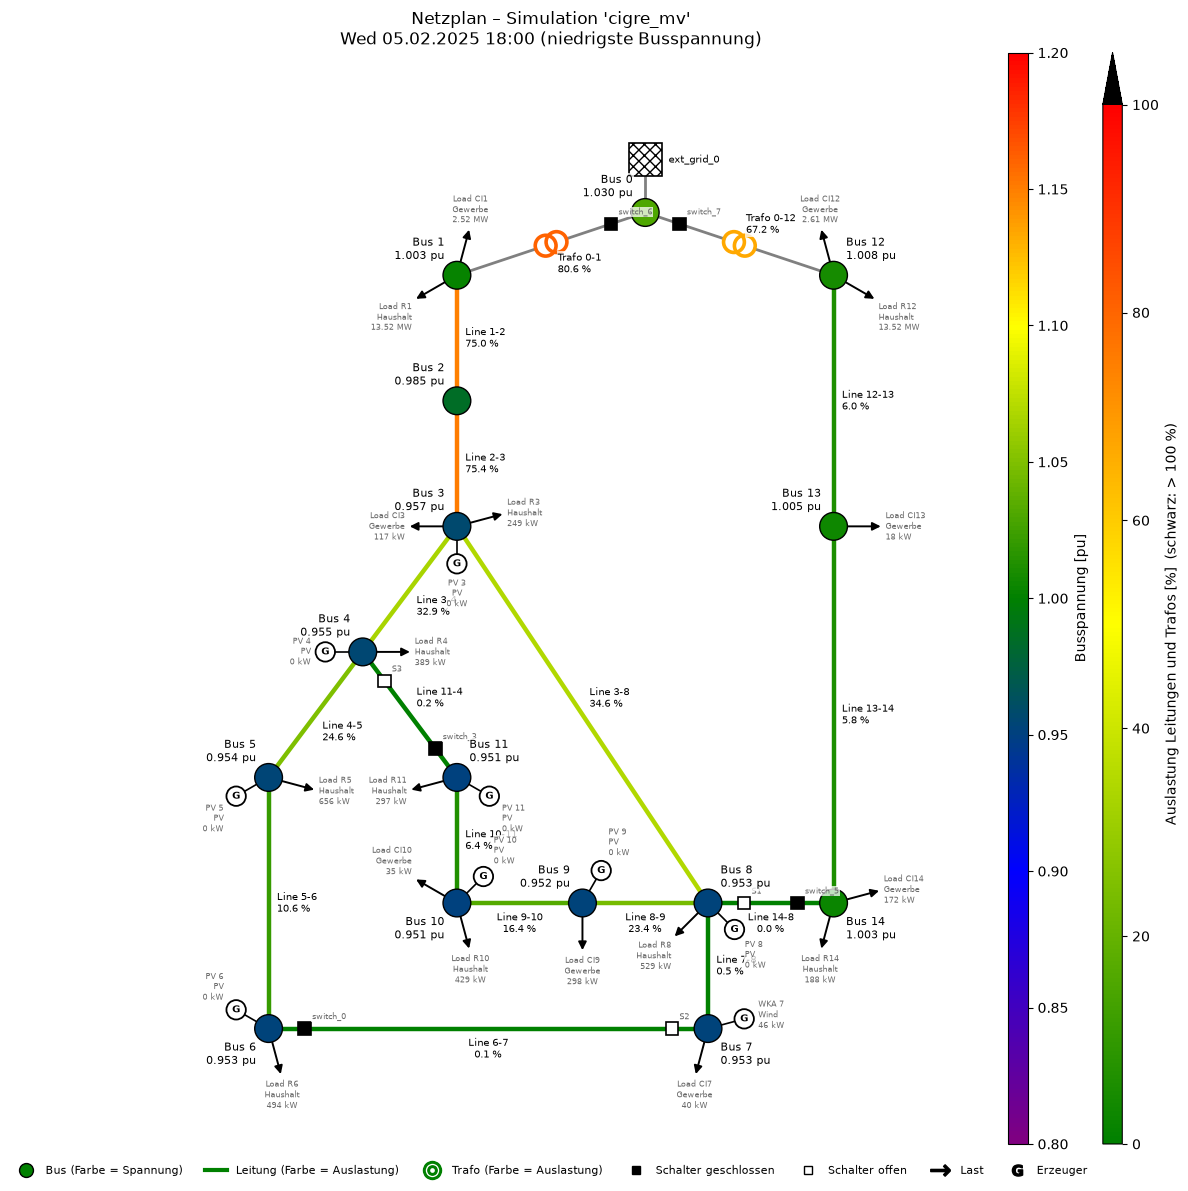

In [107]:
cigre.createDiagram(Diagram.NETWORK, time=["min"])

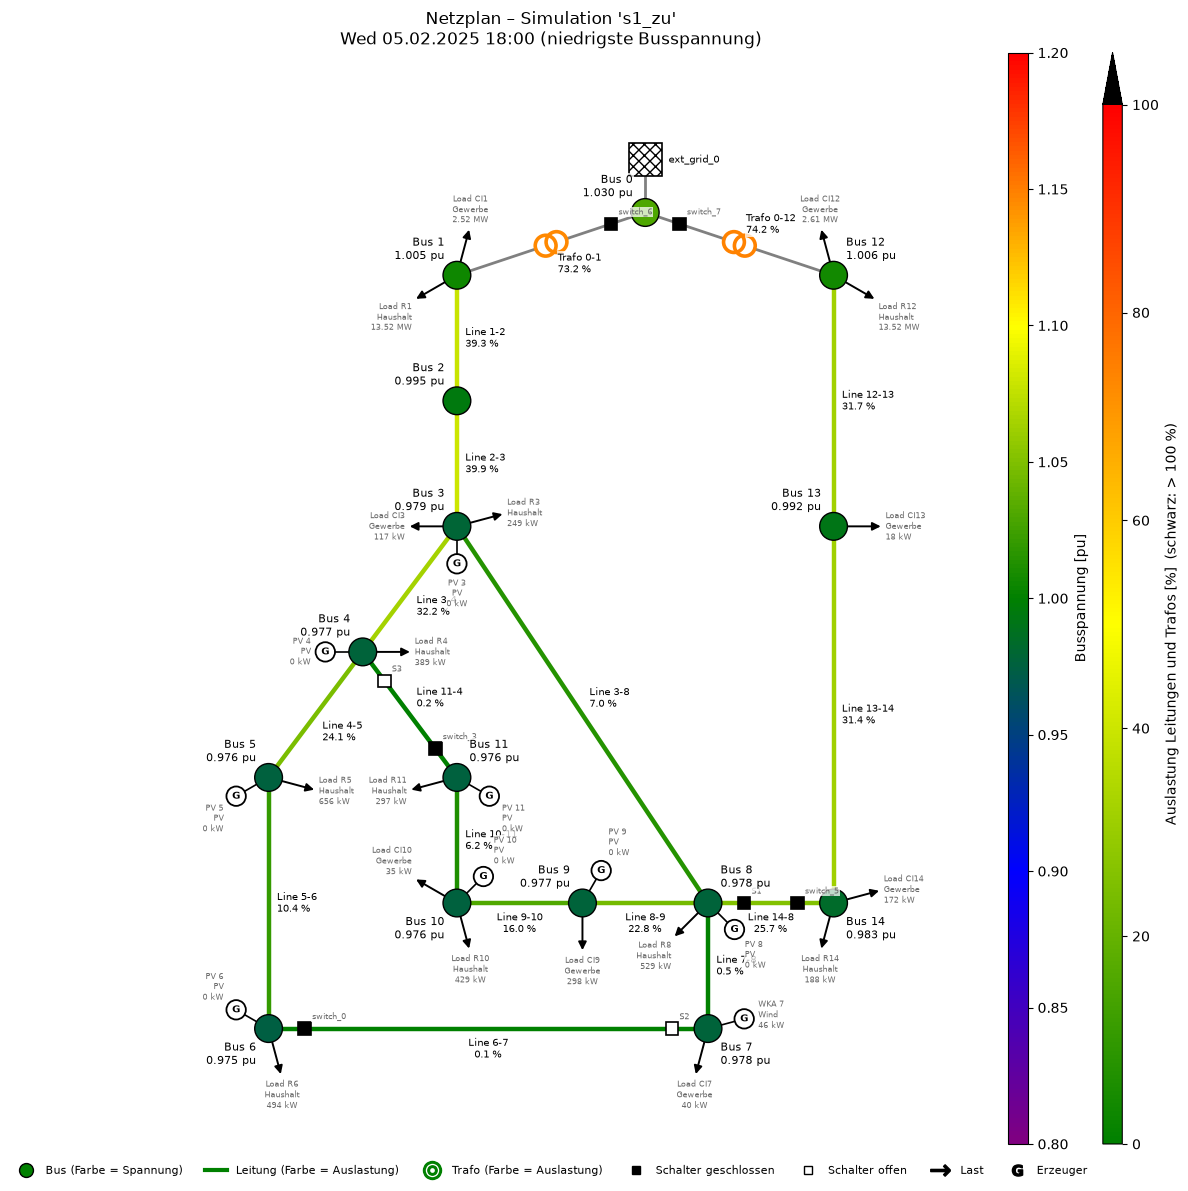

In [108]:
s1_zu.createDiagram(Diagram.NETWORK, time=["min"])

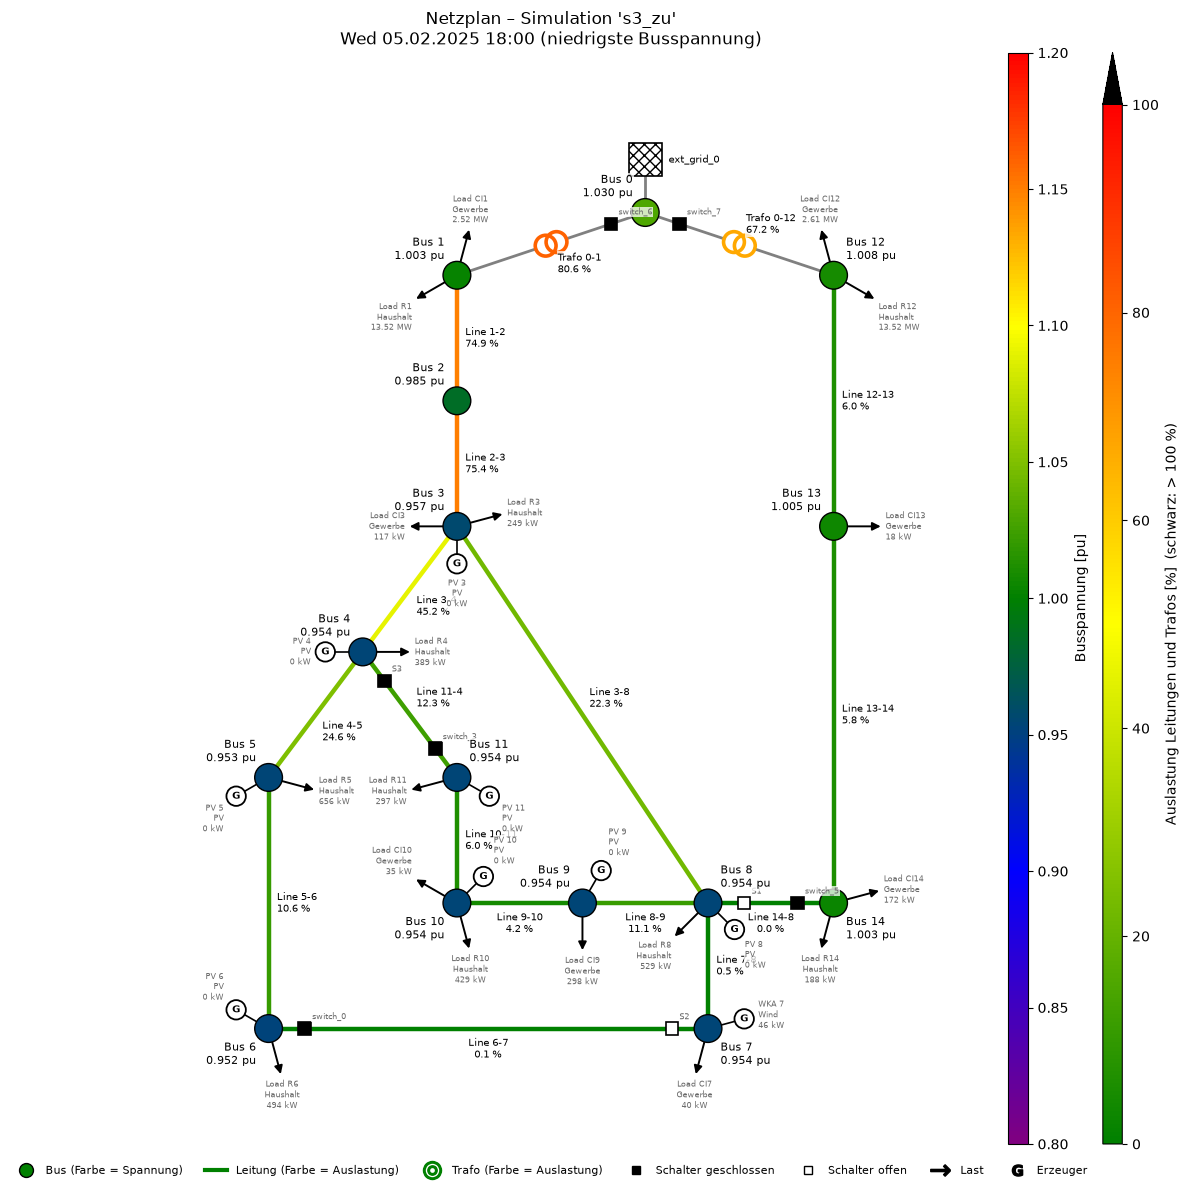

In [109]:
s3_zu.createDiagram(Diagram.NETWORK, time=["min"])

#### Netzwerk Maximale Busspannung

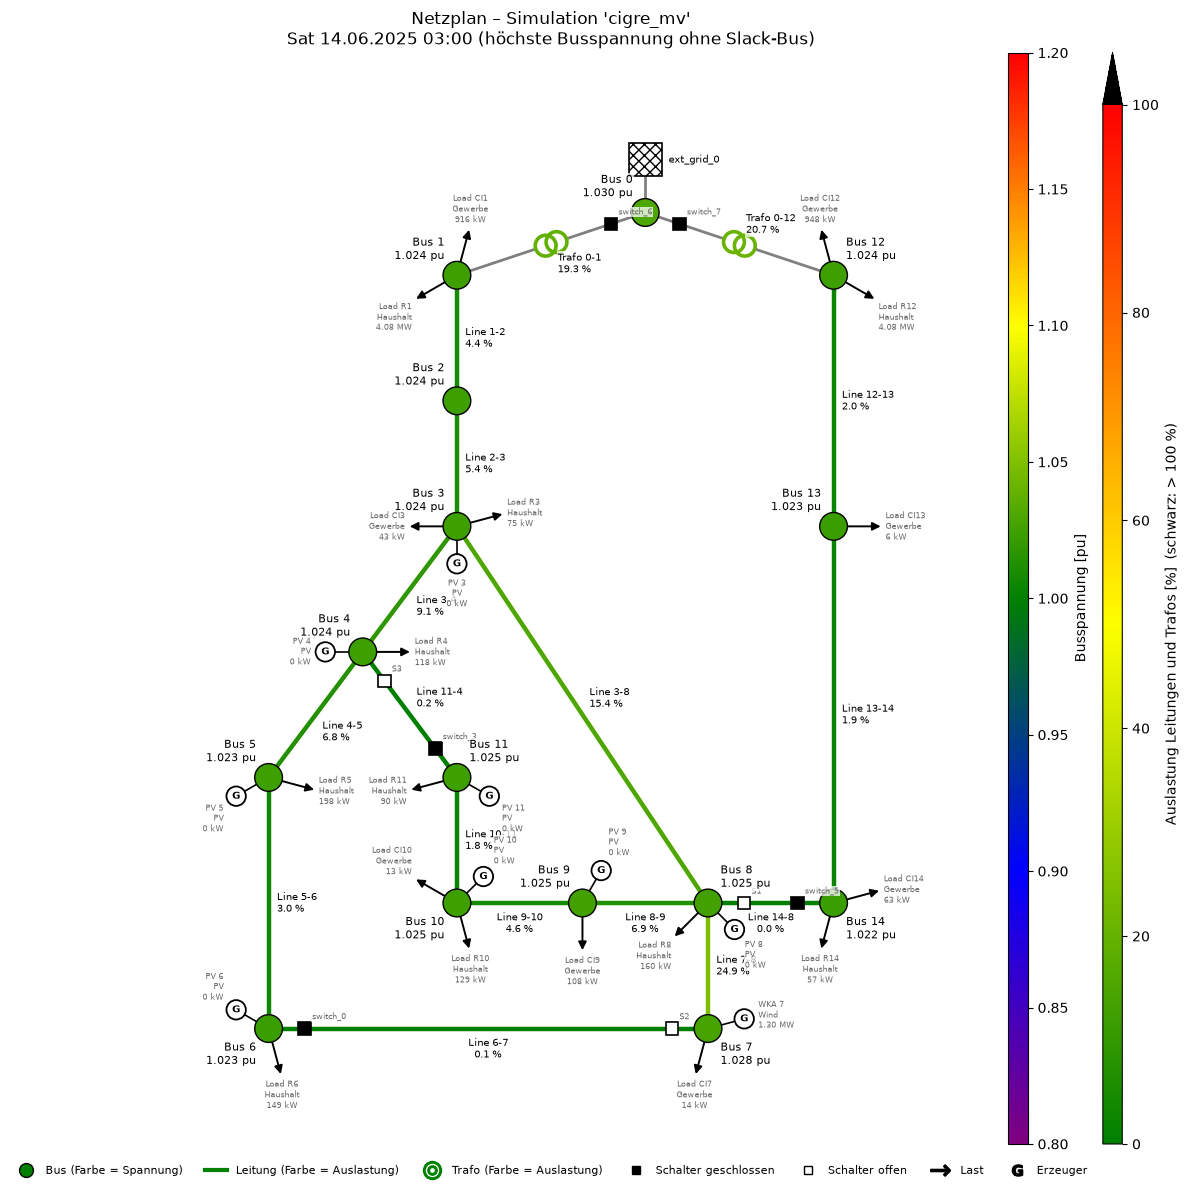

In [110]:
cigre.createDiagram(Diagram.NETWORK, time=["max"])

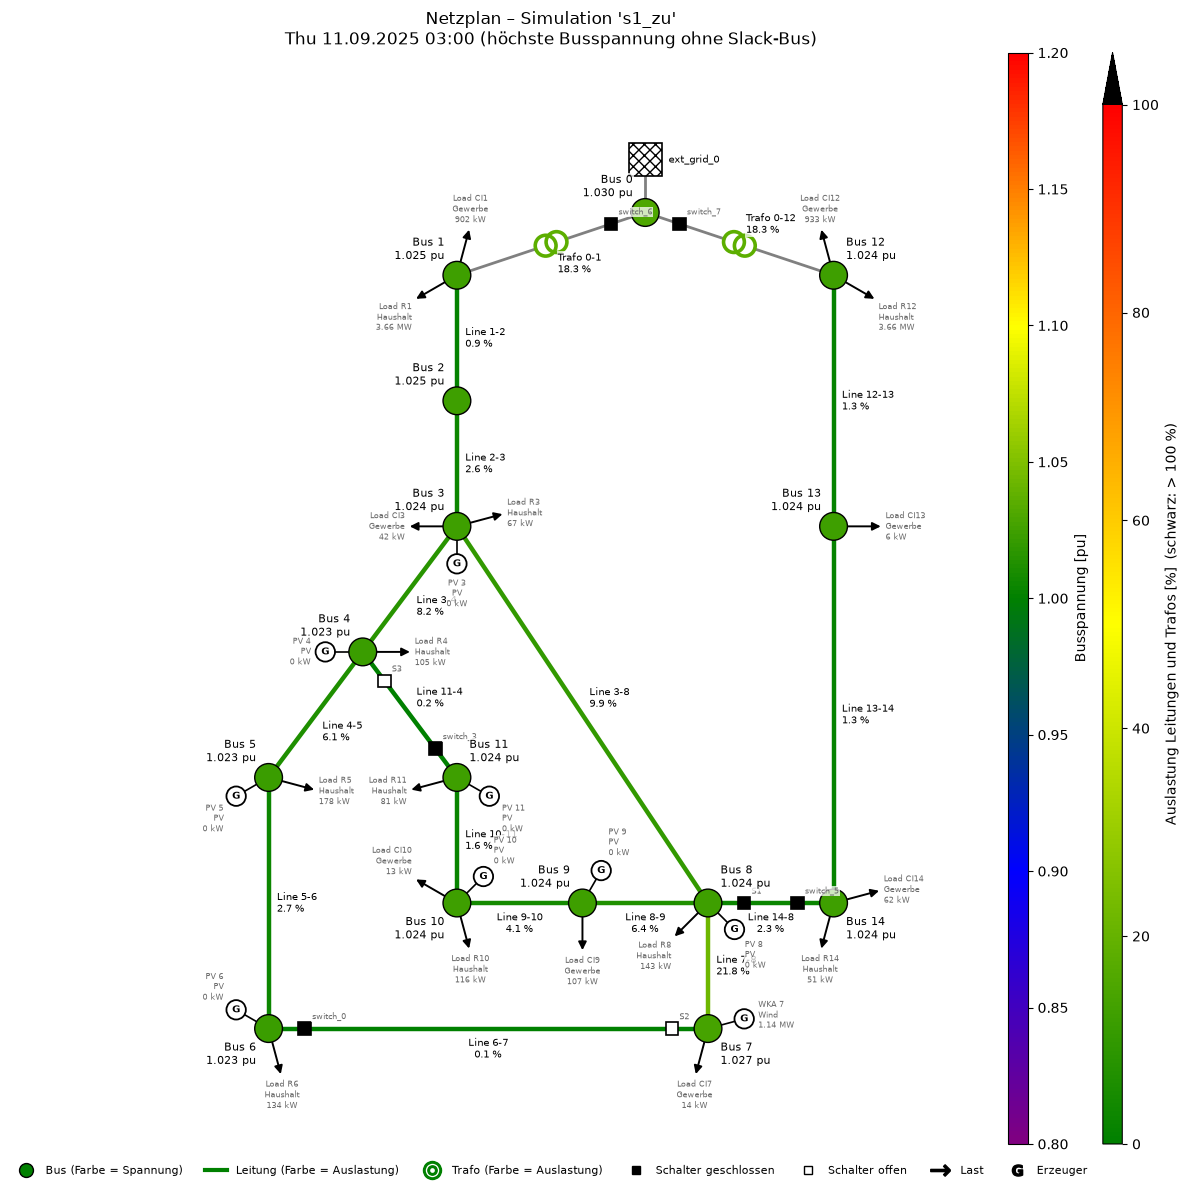

In [111]:
s1_zu.createDiagram(Diagram.NETWORK, time=["max"])

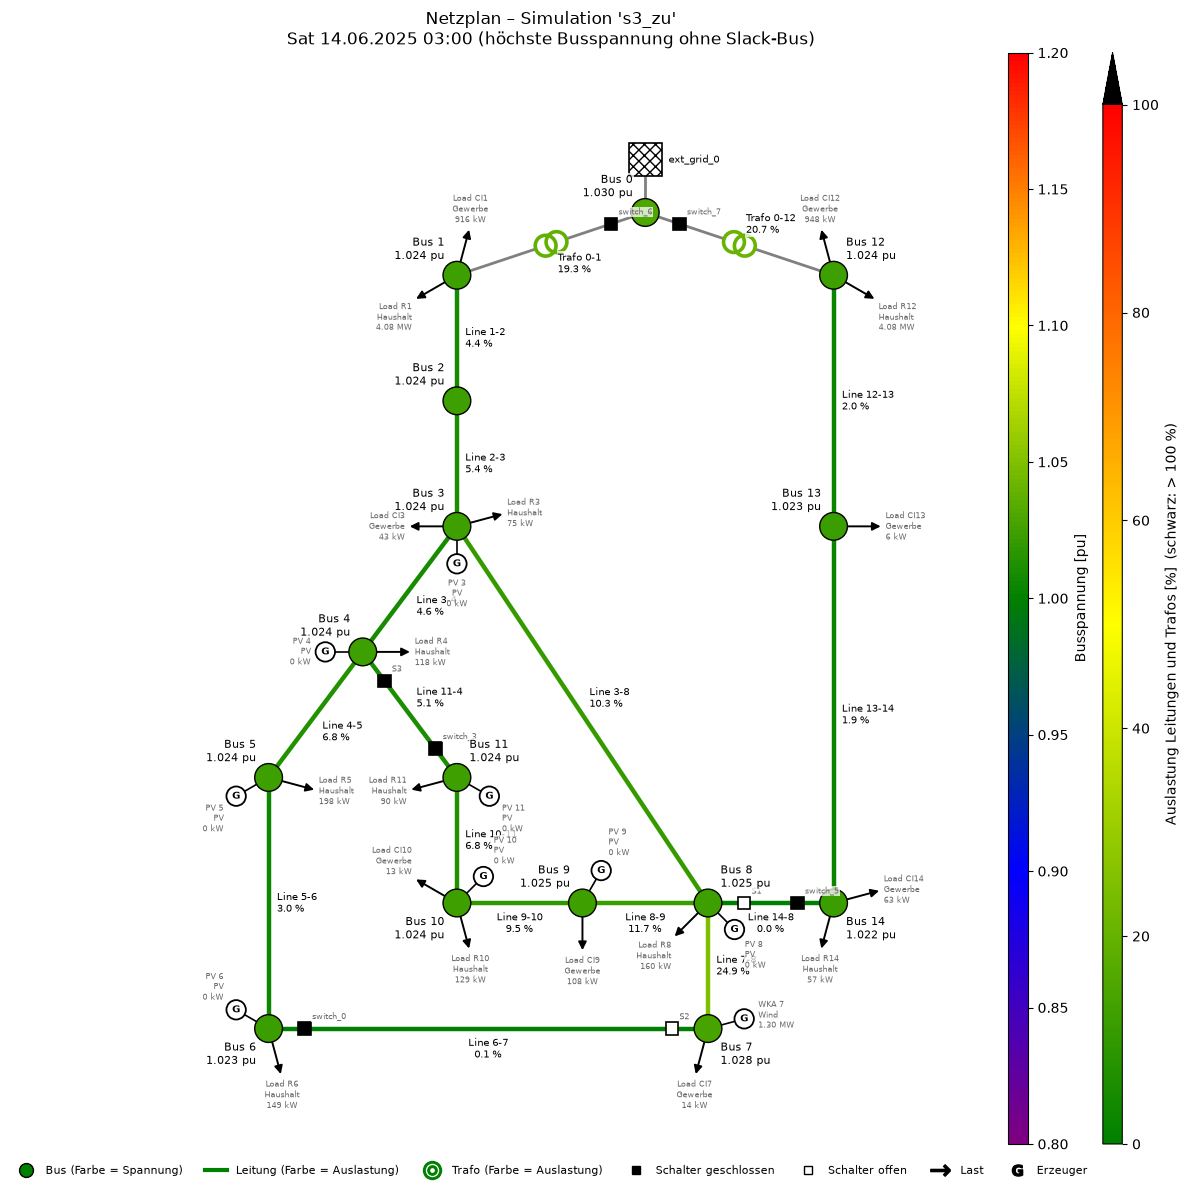

In [112]:
s3_zu.createDiagram(Diagram.NETWORK, time=["max"])

#### Netzwerk Maximale Leistungsauslastung

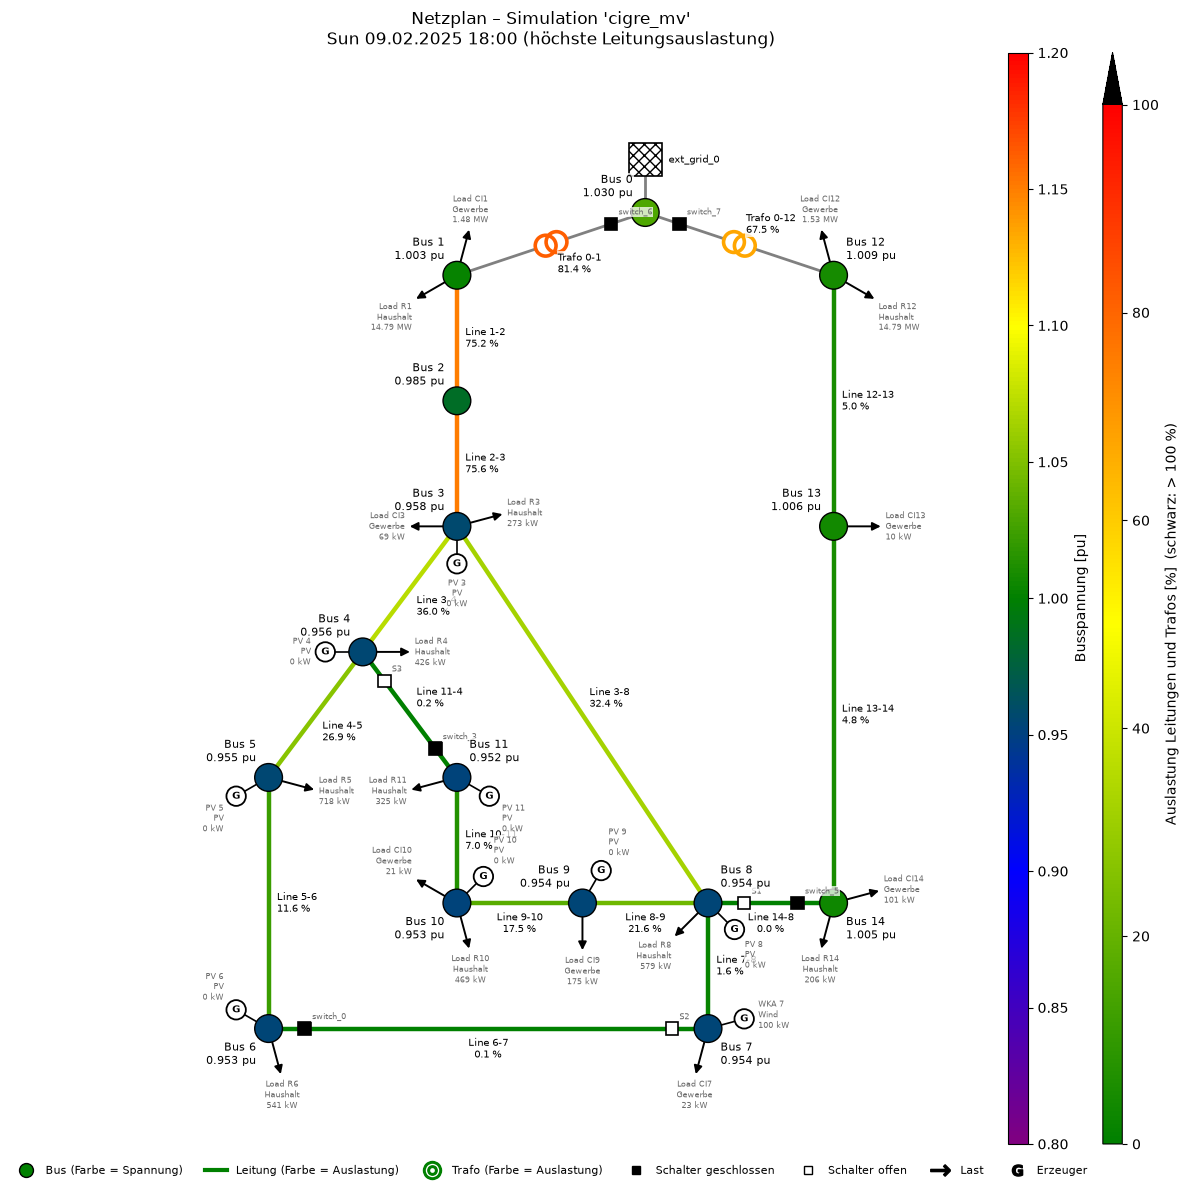

In [113]:
cigre.createDiagram(Diagram.NETWORK, time=["max_loading"])

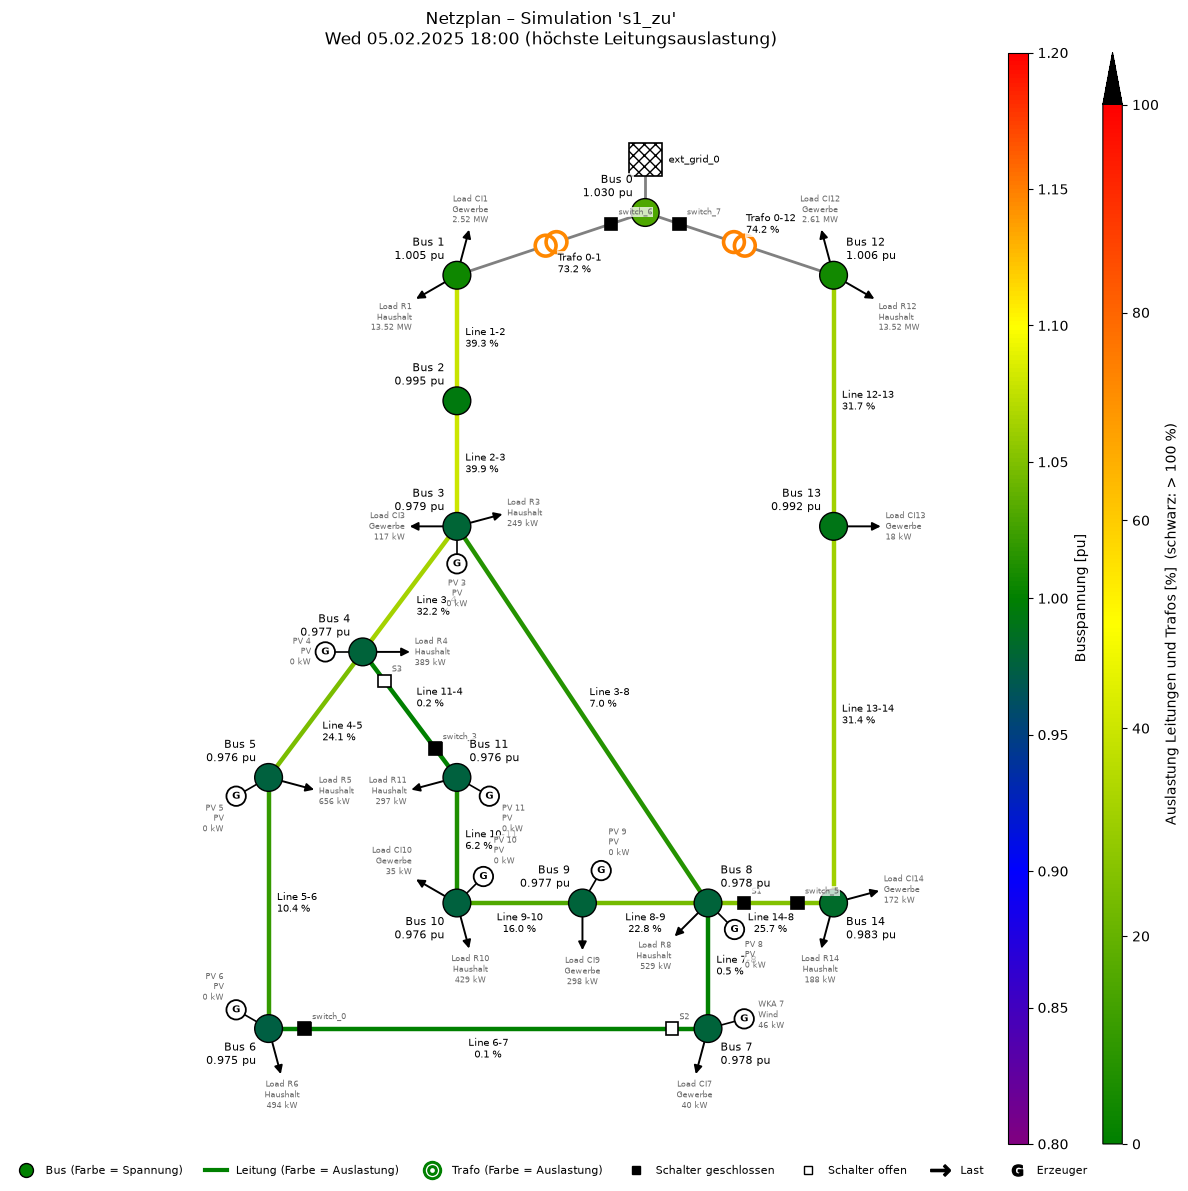

In [114]:
s1_zu.createDiagram(Diagram.NETWORK, time=["max_loading"])

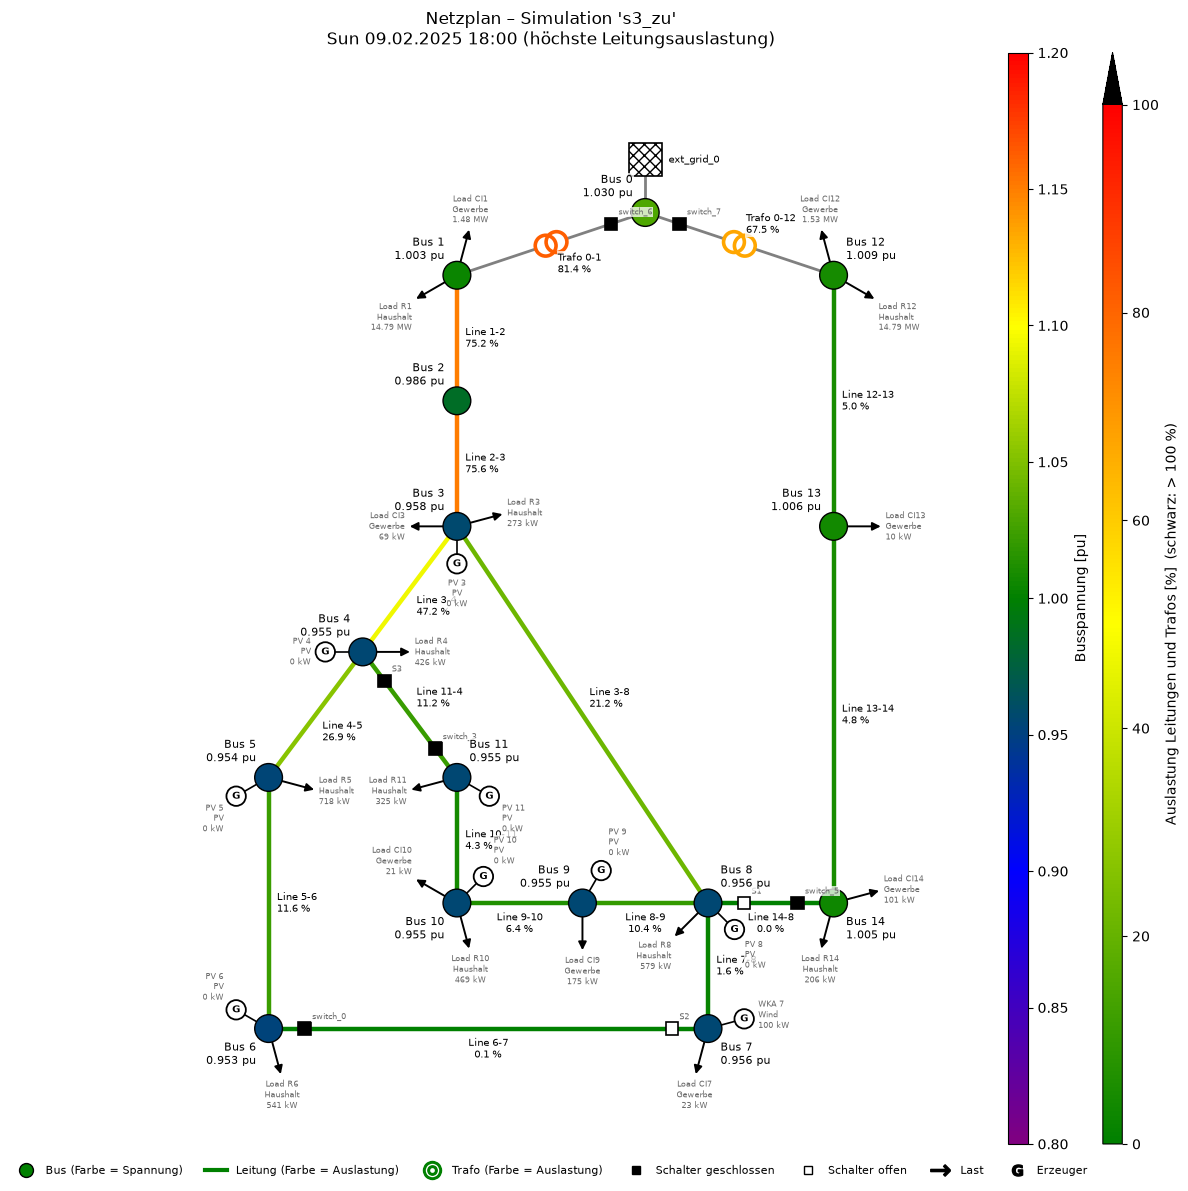

In [115]:
s3_zu.createDiagram(Diagram.NETWORK, time=["max_loading"])

#### Fazit

Die Auswrtung zeigt eindetig, dass das Netzwerk kein Problem damit hat, wenn man die Ringe schließt für einen parellel Betrieb.

Es zeigt sogar, dass die maximale Leitungsauslastung sinkt und die Busapannung an den einzelnen Bussen steigt, wenn man S1 schliesst.

### Trafo ausfall simulieren

#### Simulation durchführen

In [121]:
s1_zu_sw7_auf = cigre.copy("s1_zu_sw7_auf", overwrite=True)
s1_zu_sw7_auf.changeParameter("S1", "closed", True)
s1_zu_sw7_auf.changeParameter("switch_7", "closed", False)
s1_zu_sw7_auf.runSimulation()

s1_zu_sw6_auf = cigre.copy("s1_zu_sw6_auf", overwrite=True)
s1_zu_sw6_auf.changeParameter("S1", "closed", True)
s1_zu_sw6_auf.changeParameter("switch_6", "closed", False)
s1_zu_sw6_auf.runSimulation()

Simulation 's1_zu_sw7_auf': 2016 Lastflüsse in 119 s, nicht konvergiert: 1496 (als NaN gespeichert)
Simulation 's1_zu_sw6_auf': 2016 Lastflüsse in 110 s, nicht konvergiert: 1492 (als NaN gespeichert)


Ergebnisse: 2016 Zeitschritte (524 konvergiert), Monate: Januar, Februar, März, April, Mai, Juni, Juli, August, September, Oktober, November, Dezember
Tabellen: vm_pu, va_degree, line_loading, line_i_ka, trafo_loading, trafo_p_mw, ext_grid_p_mw, load_p_mw, sgen_p_mw, element_p_mw, info

#### Maximale Spannung

In [122]:
monatstabelle(cigre, "Spannung", "max")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
U max [pu],,,,,,,,,,,,
Bus 0,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030
Bus 1,1.022,1.022,1.023,1.023,1.024,1.024,1.024,1.024,1.025,1.024,1.023,1.023
Bus 2,1.022,1.021,1.021,1.022,1.022,1.024,1.022,1.023,1.025,1.023,1.023,1.023
Bus 3,1.021,1.020,1.017,1.019,1.018,1.024,1.019,1.022,1.025,1.021,1.022,1.022
Bus 4,1.021,1.019,1.017,1.019,1.018,1.024,1.018,1.021,1.024,1.021,1.021,1.021
Bus 5,1.020,1.019,1.017,1.019,1.018,1.023,1.018,1.021,1.024,1.021,1.021,1.021
Bus 6,1.020,1.018,1.016,1.018,1.017,1.023,1.018,1.021,1.024,1.020,1.020,1.021
Bus 7,1.025,1.023,1.020,1.022,1.020,1.028,1.020,1.024,1.028,1.024,1.025,1.026
Bus 8,1.022,1.020,1.018,1.020,1.018,1.025,1.019,1.022,1.025,1.022,1.022,1.023


In [123]:
monatstabelle(s1_zu_sw7_auf, "Spannung", "max")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
U max [pu],,,,,,,,,,,,
Bus 0,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030
Bus 1,1.006,1.003,1.007,1.008,1.012,1.012,1.012,1.012,1.014,1.011,1.010,1.007
Bus 2,0.963,0.956,0.965,0.968,0.978,0.981,0.978,0.980,0.987,0.977,0.974,0.967
Bus 3,0.898,0.885,0.901,0.906,0.925,0.932,0.926,0.931,0.943,0.925,0.918,0.906
Bus 4,0.897,0.884,0.900,0.905,0.924,0.932,0.925,0.931,0.943,0.924,0.918,0.905
Bus 5,0.897,0.883,0.900,0.905,0.924,0.932,0.925,0.930,0.943,0.924,0.918,0.905
Bus 6,0.897,0.883,0.899,0.904,0.924,0.931,0.925,0.930,0.942,0.924,0.917,0.904
Bus 7,0.884,0.869,0.886,0.890,0.911,0.922,0.914,0.920,0.935,0.913,0.906,0.893
Bus 8,0.881,0.866,0.884,0.889,0.911,0.919,0.912,0.918,0.932,0.911,0.904,0.889


In [124]:
monatstabelle(s1_zu_sw6_auf, "Spannung", "max")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
U max [pu],,,,,,,,,,,,
Bus 0,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030
Bus 1,0.766,0.741,0.775,0.790,0.826,0.832,0.825,0.832,0.854,0.819,0.807,0.781
Bus 2,0.803,0.781,0.810,0.822,0.853,0.860,0.853,0.860,0.880,0.849,0.838,0.816
Bus 3,0.863,0.846,0.866,0.873,0.897,0.906,0.898,0.904,0.920,0.896,0.888,0.873
Bus 4,0.862,0.846,0.866,0.872,0.896,0.905,0.897,0.904,0.919,0.896,0.888,0.872
Bus 5,0.862,0.845,0.865,0.872,0.896,0.905,0.897,0.903,0.919,0.895,0.888,0.872
Bus 6,0.862,0.845,0.865,0.871,0.895,0.904,0.896,0.903,0.919,0.895,0.887,0.871
Bus 7,0.886,0.871,0.887,0.890,0.911,0.923,0.914,0.921,0.935,0.914,0.908,0.895
Bus 8,0.883,0.868,0.885,0.890,0.911,0.920,0.912,0.919,0.933,0.912,0.905,0.891


#### Minimale Spannung

In [125]:
monatstabelle(cigre, "Spannung", "min")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
U min [pu],,,,,,,,,,,,
Bus 0,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030
Bus 1,1.002,1.003,1.006,1.009,1.012,1.012,1.012,1.013,1.011,1.008,1.004,1.002
Bus 2,0.985,0.985,0.990,0.996,1.001,1.000,1.001,1.002,0.999,0.993,0.986,0.985
Bus 3,0.958,0.957,0.964,0.976,0.983,0.981,0.983,0.984,0.981,0.970,0.959,0.958
Bus 4,0.956,0.955,0.963,0.975,0.982,0.980,0.982,0.983,0.979,0.969,0.958,0.956
Bus 5,0.955,0.954,0.962,0.974,0.982,0.979,0.981,0.982,0.978,0.968,0.957,0.955
Bus 6,0.953,0.953,0.961,0.973,0.981,0.978,0.980,0.981,0.977,0.967,0.955,0.954
Bus 7,0.955,0.953,0.961,0.973,0.980,0.979,0.980,0.982,0.978,0.967,0.955,0.955
Bus 8,0.954,0.953,0.961,0.973,0.980,0.979,0.980,0.982,0.978,0.967,0.955,0.954


In [126]:
monatstabelle(s1_zu_sw7_auf, "Spannung", "min")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
U min [pu],,,,,,,,,,,,
Bus 0,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030
Bus 1,0.985,0.985,0.992,0.986,0.987,0.992,0.982,0.984,0.991,0.988,0.985,0.986
Bus 2,0.910,0.907,0.925,0.908,0.912,0.925,0.899,0.905,0.922,0.917,0.906,0.910
Bus 3,0.794,0.789,0.824,0.790,0.799,0.822,0.774,0.786,0.817,0.808,0.787,0.794
Bus 4,0.794,0.788,0.823,0.789,0.798,0.822,0.773,0.785,0.817,0.807,0.786,0.793
Bus 5,0.793,0.788,0.822,0.789,0.797,0.821,0.773,0.785,0.816,0.807,0.785,0.793
Bus 6,0.792,0.787,0.822,0.788,0.797,0.820,0.772,0.784,0.815,0.806,0.785,0.792
Bus 7,0.766,0.759,0.797,0.759,0.769,0.795,0.741,0.755,0.791,0.783,0.756,0.764
Bus 8,0.764,0.758,0.797,0.759,0.769,0.795,0.741,0.754,0.790,0.780,0.755,0.764


In [127]:
monatstabelle(s1_zu_sw6_auf, "Spannung", "min")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
U min [pu],,,,,,,,,,,,
Bus 0,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030
Bus 1,0.581,0.582,0.563,0.587,0.596,0.643,0.583,0.551,0.629,0.596,0.583,0.547
Bus 2,0.641,0.640,0.624,0.644,0.652,0.692,0.640,0.612,0.681,0.655,0.640,0.610
Bus 3,0.741,0.737,0.727,0.739,0.746,0.775,0.736,0.716,0.767,0.753,0.737,0.716
Bus 4,0.740,0.737,0.726,0.738,0.745,0.774,0.735,0.715,0.767,0.752,0.736,0.715
Bus 5,0.739,0.736,0.725,0.737,0.745,0.773,0.735,0.714,0.766,0.751,0.735,0.714
Bus 6,0.738,0.735,0.724,0.737,0.744,0.773,0.734,0.713,0.765,0.750,0.734,0.714
Bus 7,0.776,0.770,0.762,0.770,0.778,0.802,0.768,0.750,0.797,0.789,0.769,0.752
Bus 8,0.774,0.770,0.761,0.770,0.777,0.802,0.768,0.750,0.796,0.785,0.769,0.751


#### Minimaler Winkel

In [128]:
monatstabelle(cigre, "Winkel", "min")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Winkel min [°],,,,,,,,,,,,
Bus 0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Bus 1,-35.33,-35.29,-34.78,-34.27,-33.59,-33.74,-33.68,-33.60,-33.91,-34.44,-35.05,-35.22
Bus 2,-36.19,-36.17,-35.58,-34.79,-34.16,-34.36,-34.27,-34.19,-34.51,-35.17,-35.89,-36.04
Bus 3,-37.58,-37.57,-36.87,-35.82,-35.07,-35.33,-35.21,-35.10,-35.46,-36.36,-37.24,-37.35
Bus 4,-37.68,-37.67,-36.95,-35.89,-35.13,-35.39,-35.27,-35.16,-35.53,-36.43,-37.32,-37.44
Bus 5,-37.75,-37.74,-37.01,-35.94,-35.17,-35.44,-35.31,-35.20,-35.57,-36.49,-37.38,-37.50
Bus 6,-37.83,-37.82,-37.08,-36.00,-35.22,-35.49,-35.36,-35.25,-35.63,-36.55,-37.45,-37.57
Bus 7,-37.73,-37.73,-37.05,-35.94,-35.16,-35.46,-35.31,-35.22,-35.55,-36.52,-37.42,-37.47
Bus 8,-37.75,-37.75,-37.04,-35.95,-35.18,-35.46,-35.32,-35.22,-35.57,-36.51,-37.42,-37.51


In [129]:
monatstabelle(s1_zu_sw7_auf, "Winkel", "min")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Winkel min [°],,,,,,,,,,,,
Bus 0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Bus 1,-35.24,-35.33,-34.87,-35.33,-35.22,-34.89,-35.45,-35.30,-34.97,-35.07,-35.36,-35.26
Bus 2,-37.74,-37.97,-37.33,-38.01,-37.82,-37.34,-38.16,-37.90,-37.43,-37.43,-38.04,-37.86
Bus 3,-42.57,-43.12,-41.94,-43.24,-42.83,-41.97,-43.54,-42.99,-42.09,-41.92,-43.29,-42.90
Bus 4,-42.63,-43.18,-41.99,-43.30,-42.89,-42.02,-43.60,-43.04,-42.14,-41.98,-43.34,-42.96
Bus 5,-42.67,-43.22,-42.03,-43.34,-42.93,-42.06,-43.64,-43.08,-42.18,-42.02,-43.38,-43.00
Bus 6,-42.72,-43.27,-42.07,-43.38,-42.98,-42.10,-43.68,-43.12,-42.22,-42.07,-43.43,-43.04
Bus 7,-43.84,-44.70,-43.38,-44.92,-44.35,-43.42,-45.31,-44.57,-43.47,-42.94,-44.95,-44.42
Bus 8,-44.10,-44.77,-43.38,-44.91,-44.42,-43.41,-45.31,-44.64,-43.54,-43.31,-44.97,-44.51


In [130]:
monatstabelle(s1_zu_sw6_auf, "Winkel", "min")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Winkel min [°],,,,,,,,,,,,
Bus 0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Bus 1,-49.79,-50.02,-50.46,-49.97,-49.55,-47.64,-49.76,-51.39,-48.19,-49.12,-50.06,-51.10
Bus 2,-45.06,-45.42,-45.53,-45.47,-45.14,-43.97,-45.27,-46.30,-44.27,-44.54,-45.50,-45.93
Bus 3,-39.31,-39.69,-39.53,-39.85,-39.61,-39.18,-39.68,-40.13,-39.21,-38.89,-39.81,-39.73
Bus 4,-39.37,-39.76,-39.60,-39.91,-39.68,-39.23,-39.74,-40.21,-39.27,-38.95,-39.88,-39.80
Bus 5,-39.41,-39.80,-39.64,-39.96,-39.72,-39.27,-39.79,-40.25,-39.32,-38.99,-39.93,-39.84
Bus 6,-39.46,-39.86,-39.70,-40.01,-39.78,-39.32,-39.84,-40.31,-39.37,-39.03,-39.98,-39.90
Bus 7,-37.78,-38.05,-37.82,-38.30,-38.01,-37.82,-38.17,-38.48,-37.82,-37.56,-38.24,-37.97
Bus 8,-37.85,-38.12,-37.92,-38.30,-38.08,-37.81,-38.16,-38.48,-37.81,-37.58,-38.25,-38.08


#### Maximaler Winkel

In [131]:
monatstabelle(cigre, "Winkel", "max")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Winkel max [°],,,,,,,,,,,,
Bus 0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Bus 1,-31.53,-31.64,-31.58,-31.54,-31.42,-31.25,-31.39,-31.30,-31.15,-31.35,-31.40,-31.47
Bus 2,-31.46,-31.60,-31.66,-31.56,-31.53,-31.18,-31.49,-31.31,-31.10,-31.36,-31.39,-31.39
Bus 3,-31.33,-31.52,-31.77,-31.56,-31.68,-31.05,-31.63,-31.31,-31.01,-31.35,-31.31,-31.25
Bus 4,-31.36,-31.55,-31.79,-31.59,-31.71,-31.07,-31.65,-31.34,-31.03,-31.37,-31.34,-31.28
Bus 5,-31.38,-31.57,-31.81,-31.61,-31.72,-31.09,-31.67,-31.35,-31.05,-31.39,-31.36,-31.30
Bus 6,-31.41,-31.60,-31.84,-31.64,-31.75,-31.11,-31.69,-31.37,-31.07,-31.41,-31.39,-31.32
Bus 7,-30.97,-31.18,-31.55,-31.31,-31.55,-30.73,-31.47,-31.08,-30.73,-31.10,-30.97,-30.89
Bus 8,-31.21,-31.41,-31.71,-31.49,-31.65,-30.94,-31.59,-31.24,-30.92,-31.27,-31.20,-31.13


In [132]:
monatstabelle(s1_zu_sw7_auf, "Winkel", "max")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Winkel max [°],,,,,,,,,,,,
Bus 0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Bus 1,-33.58,-33.85,-33.53,-33.42,-33.00,-32.85,-32.99,-32.88,-32.58,-33.02,-33.16,-33.42
Bus 2,-35.18,-35.60,-35.18,-35.10,-34.48,-34.10,-34.40,-34.19,-33.72,-34.40,-34.58,-34.94
Bus 3,-37.95,-38.68,-38.05,-37.87,-36.99,-36.21,-36.79,-36.40,-35.62,-36.73,-37.02,-37.55
Bus 4,-37.99,-38.72,-38.09,-37.91,-37.02,-36.24,-36.82,-36.43,-35.65,-36.76,-37.05,-37.59
Bus 5,-38.01,-38.75,-38.11,-37.93,-37.04,-36.26,-36.84,-36.45,-35.67,-36.78,-37.07,-37.61
Bus 6,-38.04,-38.78,-38.14,-37.96,-37.07,-36.28,-36.87,-36.47,-35.69,-36.81,-37.10,-37.64
Bus 7,-38.42,-39.27,-38.68,-38.42,-37.56,-36.52,-37.33,-36.81,-35.92,-37.16,-37.47,-37.98
Bus 8,-38.73,-39.57,-38.87,-38.66,-37.70,-36.78,-37.47,-37.01,-36.14,-37.38,-37.70,-38.29


In [133]:
monatstabelle(s1_zu_sw6_auf, "Winkel", "max")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Winkel max [°],,,,,,,,,,,,
Bus 0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Bus 1,-42.07,-43.16,-41.83,-41.37,-39.81,-39.30,-39.77,-39.38,-38.33,-39.93,-40.40,-41.41
Bus 2,-39.69,-40.53,-39.62,-39.37,-38.16,-37.59,-38.06,-37.71,-36.85,-38.13,-38.48,-39.20
Bus 3,-36.37,-36.89,-36.49,-36.36,-35.74,-35.11,-35.58,-35.27,-34.67,-35.52,-35.72,-36.08
Bus 4,-36.41,-36.93,-36.53,-36.40,-35.78,-35.15,-35.62,-35.30,-34.70,-35.56,-35.76,-36.11
Bus 5,-36.44,-36.96,-36.56,-36.42,-35.80,-35.17,-35.64,-35.33,-34.72,-35.58,-35.78,-36.14
Bus 6,-36.47,-37.00,-36.59,-36.46,-35.83,-35.19,-35.66,-35.35,-34.74,-35.61,-35.81,-36.17
Bus 7,-35.06,-35.48,-35.36,-35.17,-34.82,-34.09,-34.69,-34.32,-33.77,-34.51,-34.65,-34.83
Bus 8,-35.37,-35.79,-35.55,-35.41,-34.95,-34.35,-34.82,-34.52,-33.99,-34.72,-34.88,-35.13


#### Maximale Leitungsauslastung

In [134]:
monatstabelle(cigre, "Leitung", "max")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Leitung max [%],,,,,,,,,,,,
Line 1-2,74.7,75.2,69.0,57.1,48.8,52.0,49.9,48.9,52.8,63.4,73.1,72.3
Line 2-3,75.1,75.6,69.4,57.5,49.2,52.4,50.3,49.3,53.1,63.8,73.5,72.7
Line 3-4,36.5,36.0,30.9,29.5,24.7,23.6,23.7,22.7,25.4,29.5,34.1,34.1
Line 4-5,27.3,26.9,23.1,22.0,18.4,17.6,17.7,16.9,19.0,22.0,25.5,25.5
Line 5-6,11.8,11.6,10.0,9.5,8.0,7.6,7.6,7.3,8.2,9.5,11.0,11.0
Line 7-8,29.9,29.6,20.8,26.0,28.6,25.9,14.4,21.9,27.8,27.0,30.1,29.9
Line 8-9,24.2,23.7,21.8,20.8,19.0,18.7,18.4,18.2,19.1,20.5,23.7,24.6
Line 9-10,17.7,17.5,15.3,14.3,12.0,11.5,11.5,11.0,12.3,14.3,16.6,16.6
Line 10-11,7.1,7.0,6.0,5.7,4.8,4.6,4.6,4.5,5.0,5.7,6.6,6.6


In [135]:
monatstabelle(s1_zu_sw7_auf, "Leitung", "max")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Leitung max [%],,,,,,,,,,,,
Line 1-2,279.4,289.2,254.5,289.7,279.6,255.6,304.0,290.1,259.6,262.9,292.4,283.5
Line 2-3,279.9,289.7,255.0,290.3,280.2,256.1,304.6,290.6,260.1,263.5,292.9,284.0
Line 3-4,18.0,17.6,16.0,17.5,17.6,15.7,16.0,17.5,16.7,18.2,17.7,17.2
Line 4-5,13.4,13.2,11.9,13.1,13.1,11.7,11.9,13.1,12.4,13.6,13.3,12.9
Line 5-6,5.8,5.7,5.2,5.7,5.7,5.1,5.2,5.7,5.4,5.9,5.7,5.6
Line 7-8,36.8,34.5,24.6,32.3,21.8,29.0,17.6,21.4,32.5,33.2,32.7,36.2
Line 8-9,13.7,12.6,11.8,12.9,12.1,11.6,14.1,14.0,11.7,12.4,12.8,13.1
Line 9-10,9.3,9.1,8.2,9.0,9.0,8.1,8.5,9.0,8.5,9.3,9.1,8.9
Line 10-11,3.6,3.5,3.2,3.5,3.5,3.1,3.2,3.5,3.3,3.6,3.5,3.5


In [136]:
monatstabelle(s1_zu_sw6_auf, "Leitung", "max")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Leitung max [%],,,,,,,,,,,,
Line 1-2,252.5,245.6,257.4,240.8,238.6,212.0,241.6,259.3,222.0,248.7,243.5,263.8
Line 2-3,252.4,245.4,257.2,240.7,238.4,211.8,241.4,259.1,221.8,248.5,243.3,263.7
Line 3-4,19.3,18.9,18.3,18.8,18.9,16.7,16.8,19.5,17.8,19.6,19.0,18.4
Line 4-5,14.4,14.1,13.7,14.0,14.1,12.5,12.6,14.6,13.3,14.7,14.2,13.8
Line 5-6,6.2,6.1,5.9,6.1,6.1,5.4,5.4,6.3,5.7,6.3,6.1,6.0
Line 7-8,36.3,34.4,24.5,32.1,21.7,28.9,17.4,21.3,32.4,33.0,32.6,35.8
Line 8-9,13.4,12.4,13.6,12.7,12.0,11.5,13.6,13.6,11.6,12.3,12.6,13.8
Line 9-10,9.1,9.0,8.8,8.9,8.9,8.0,8.2,9.2,8.5,9.2,9.0,8.9
Line 10-11,3.6,3.5,3.4,3.5,3.5,3.1,3.1,3.6,3.3,3.6,3.5,3.4


#### Maximale Trafo Auslastung

In [137]:
monatstabelle(cigre, "Trafo", "max")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Trafo max [%],,,,,,,,,,,,
Trafo 0-1,82.0,81.4,73.6,65.7,55.2,57.5,56.6,55.4,60.1,68.3,77.9,80.5
Trafo 0-12,68.4,67.5,61.1,57.3,49.1,48.2,47.6,46.6,50.8,57.2,65.4,67.7


In [138]:
monatstabelle(s1_zu_sw7_auf, "Trafo", "max")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Trafo max [%],,,,,,,,,,,,
Trafo 0-1,85.3,86.6,78.2,86.4,84.5,78.5,89.1,86.5,79.9,82.2,87.0,85.3
Trafo 0-12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [139]:
monatstabelle(s1_zu_sw6_auf, "Trafo", "max")

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Trafo max [%],,,,,,,,,,,,
Trafo 0-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Trafo 0-12,85.1,86.0,87.8,85.8,84.3,78.3,86.1,90.2,79.9,82.7,86.2,89.9


#### Netzwerk Minimale Busspannung

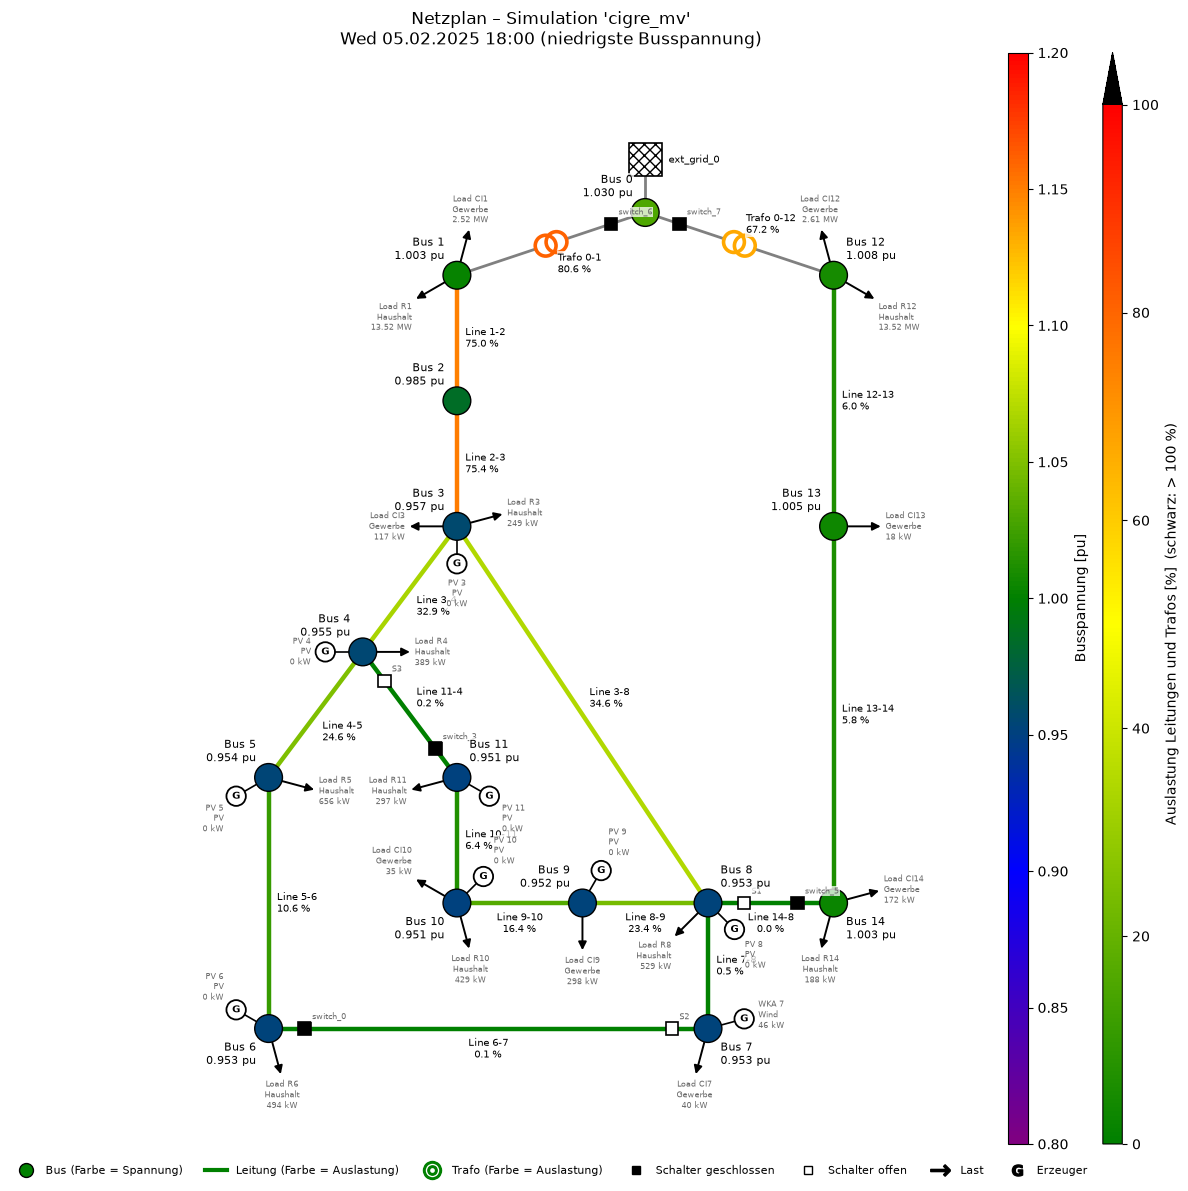

In [140]:
cigre.createDiagram(Diagram.NETWORK, time=["min"])

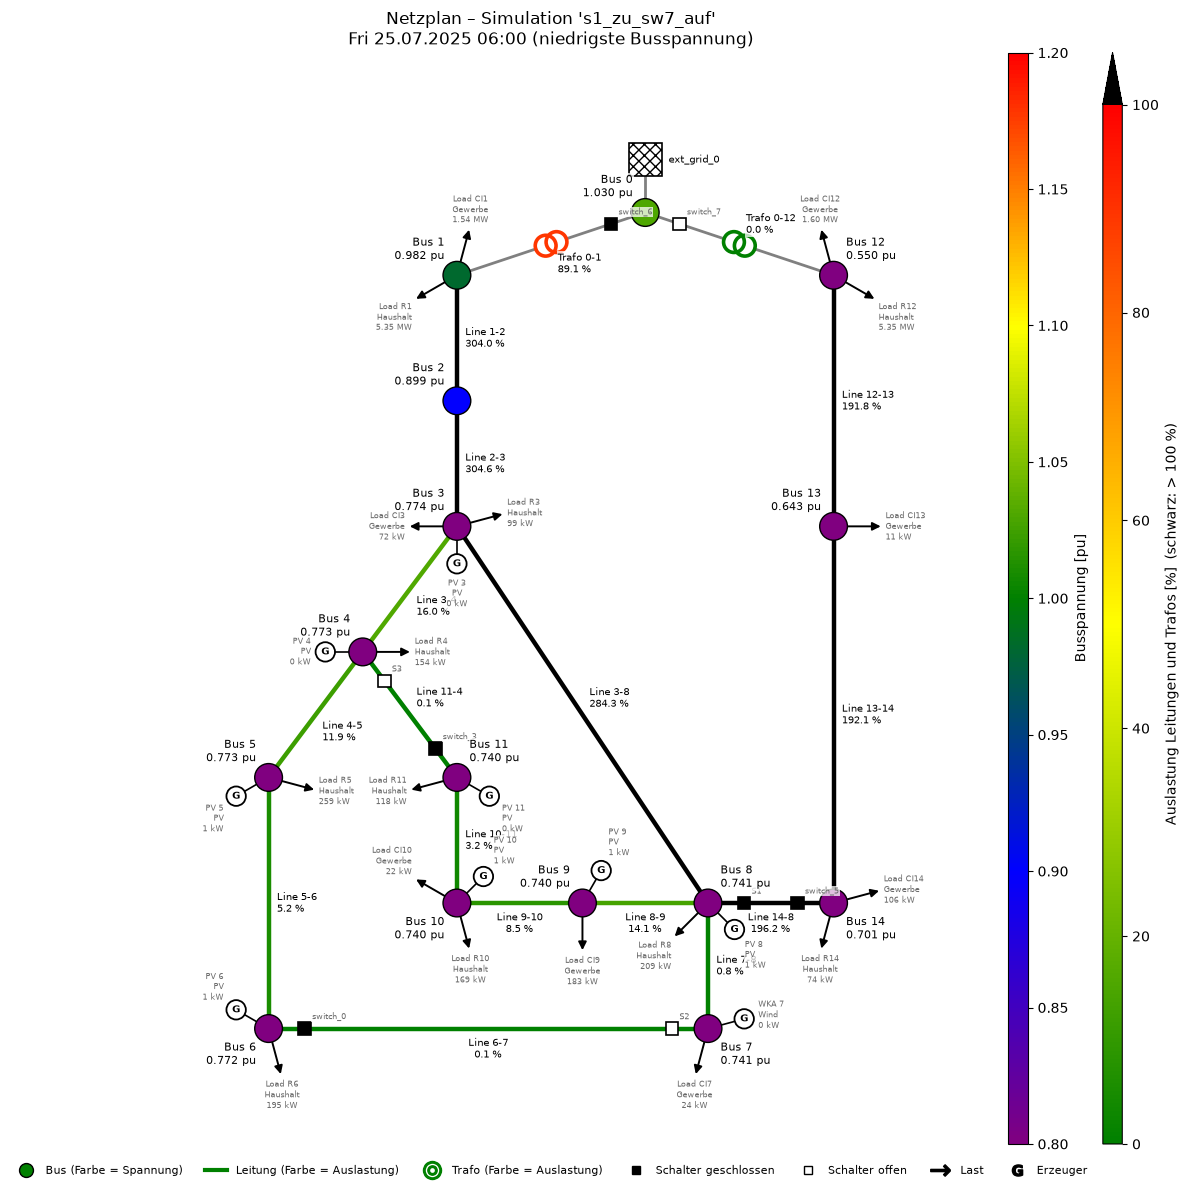

In [141]:
s1_zu_sw7_auf.createDiagram(Diagram.NETWORK, time=["min"])

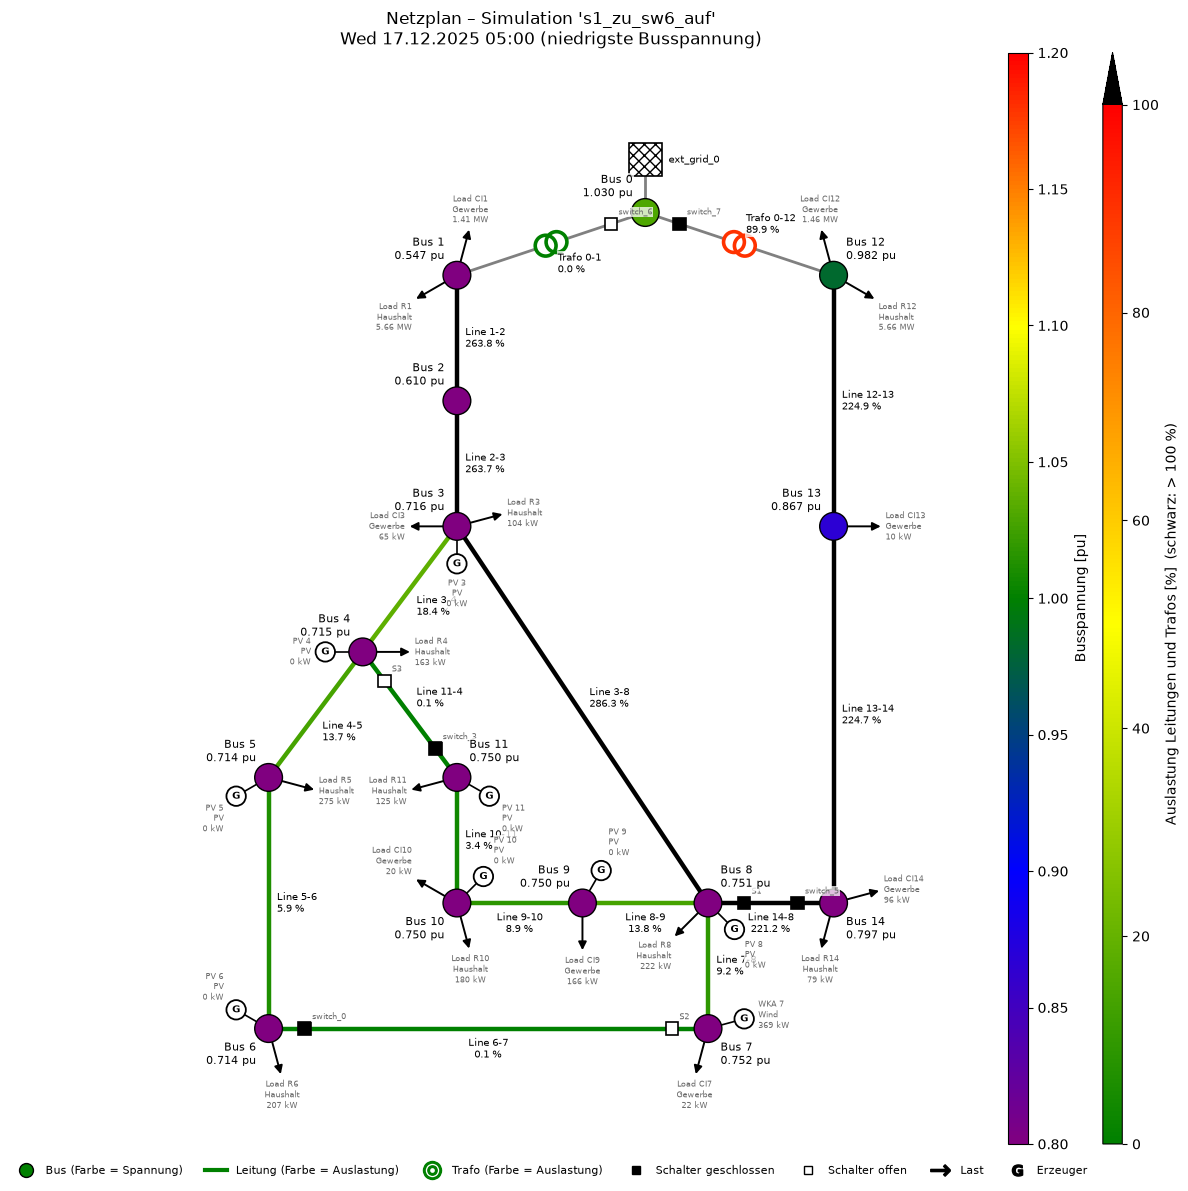

In [142]:
s1_zu_sw6_auf.createDiagram(Diagram.NETWORK, time=["min"])

#### Netzwerk Maximale Busspannung

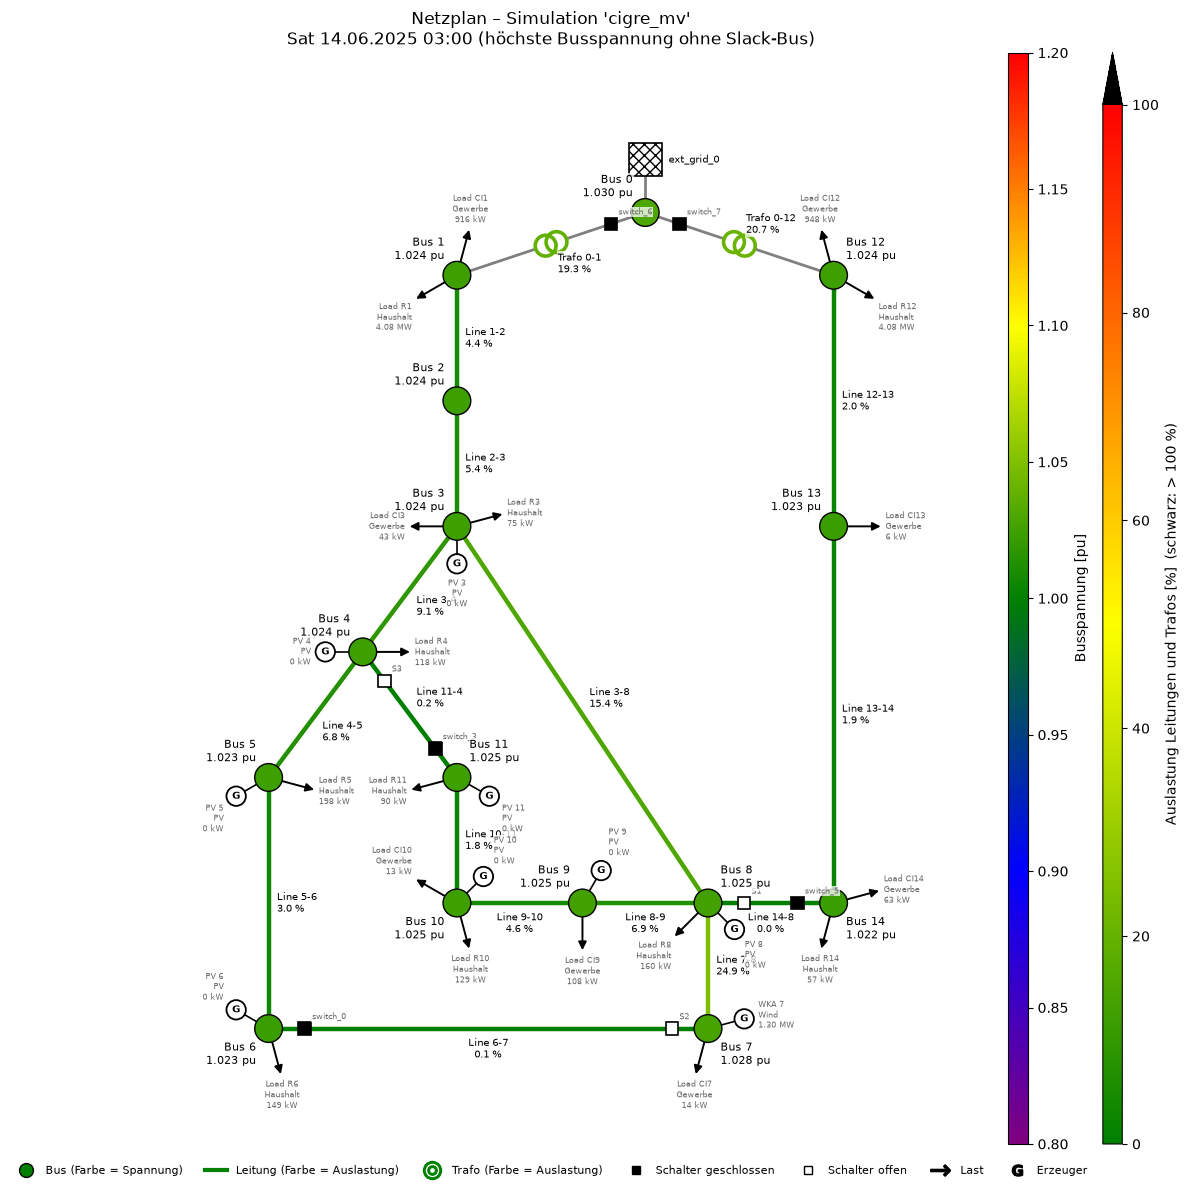

In [143]:
cigre.createDiagram(Diagram.NETWORK, time=["max"])

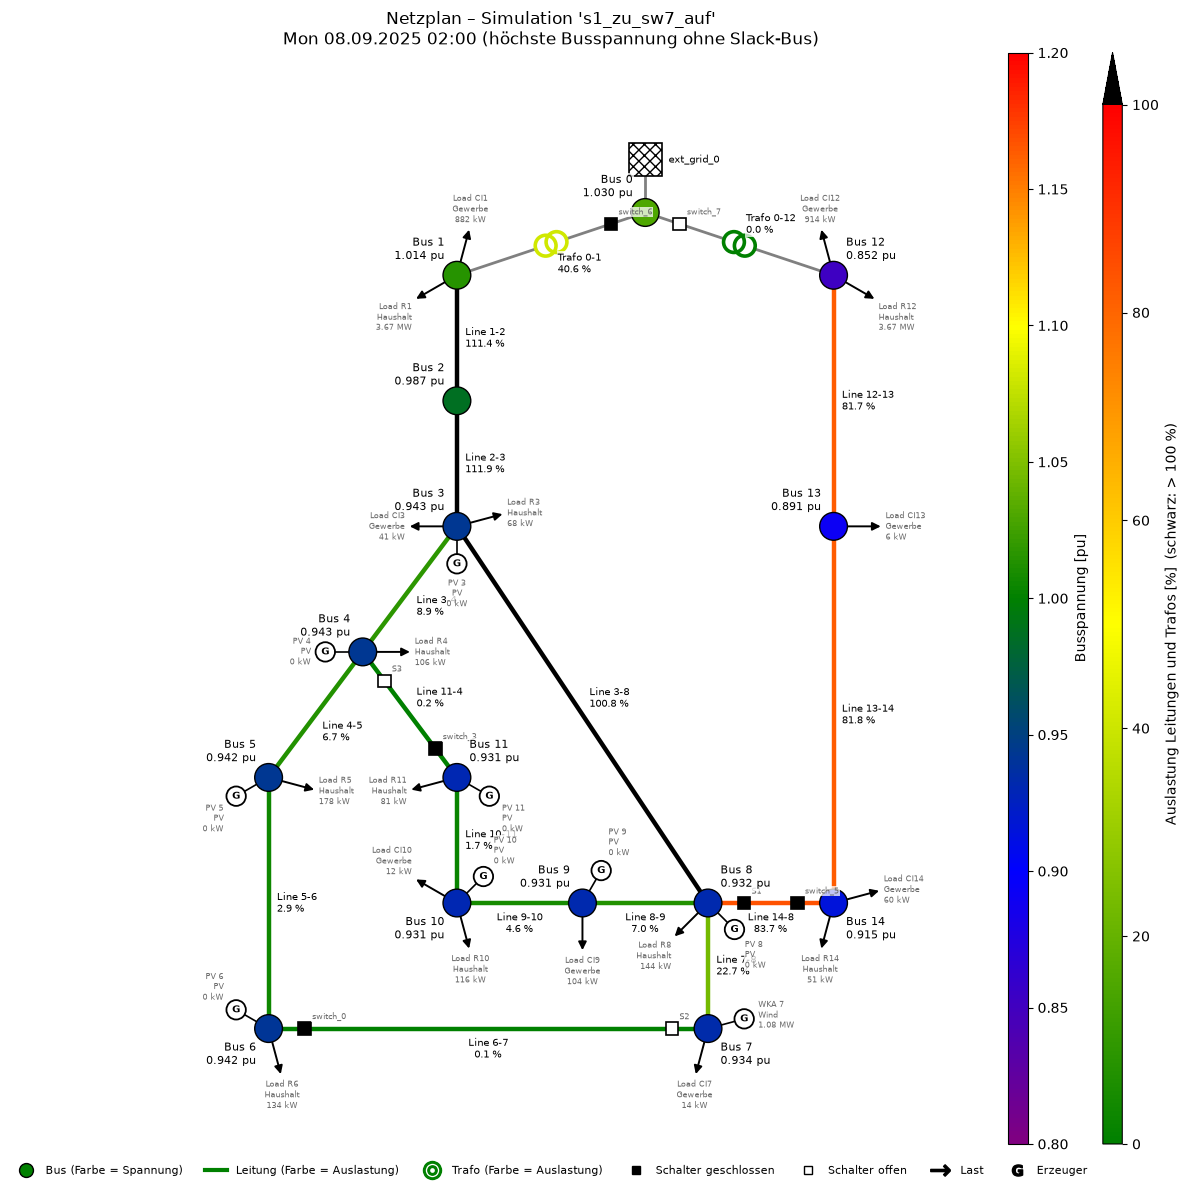

In [144]:
s1_zu_sw7_auf.createDiagram(Diagram.NETWORK, time=["max"])

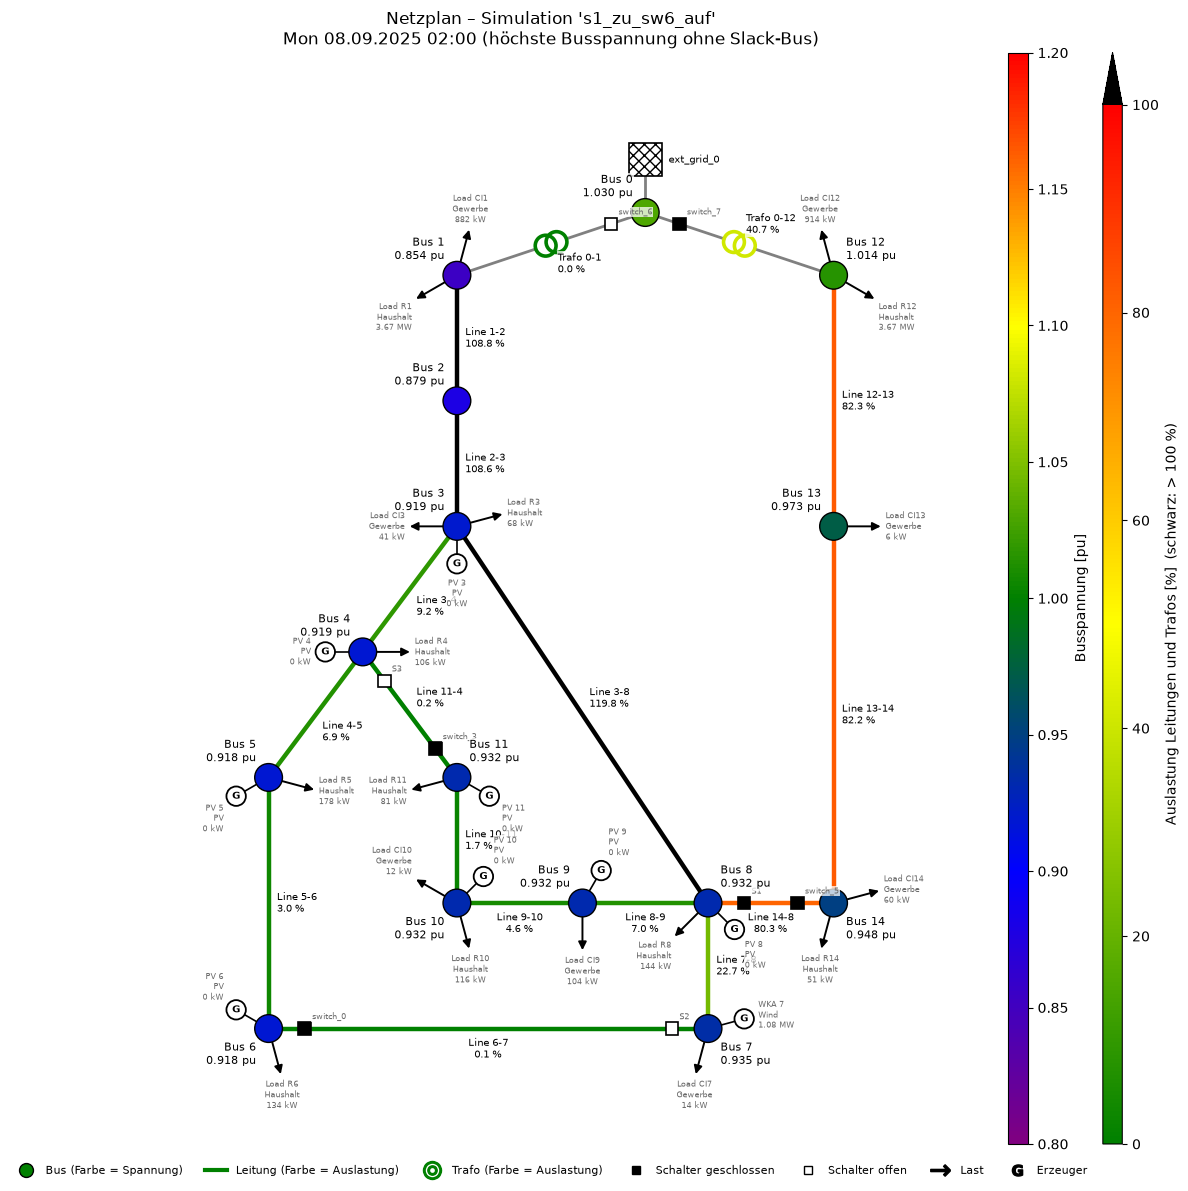

In [145]:
s1_zu_sw6_auf.createDiagram(Diagram.NETWORK, time=["max"])

#### Netzwerk Maximale Leistungsauslastung

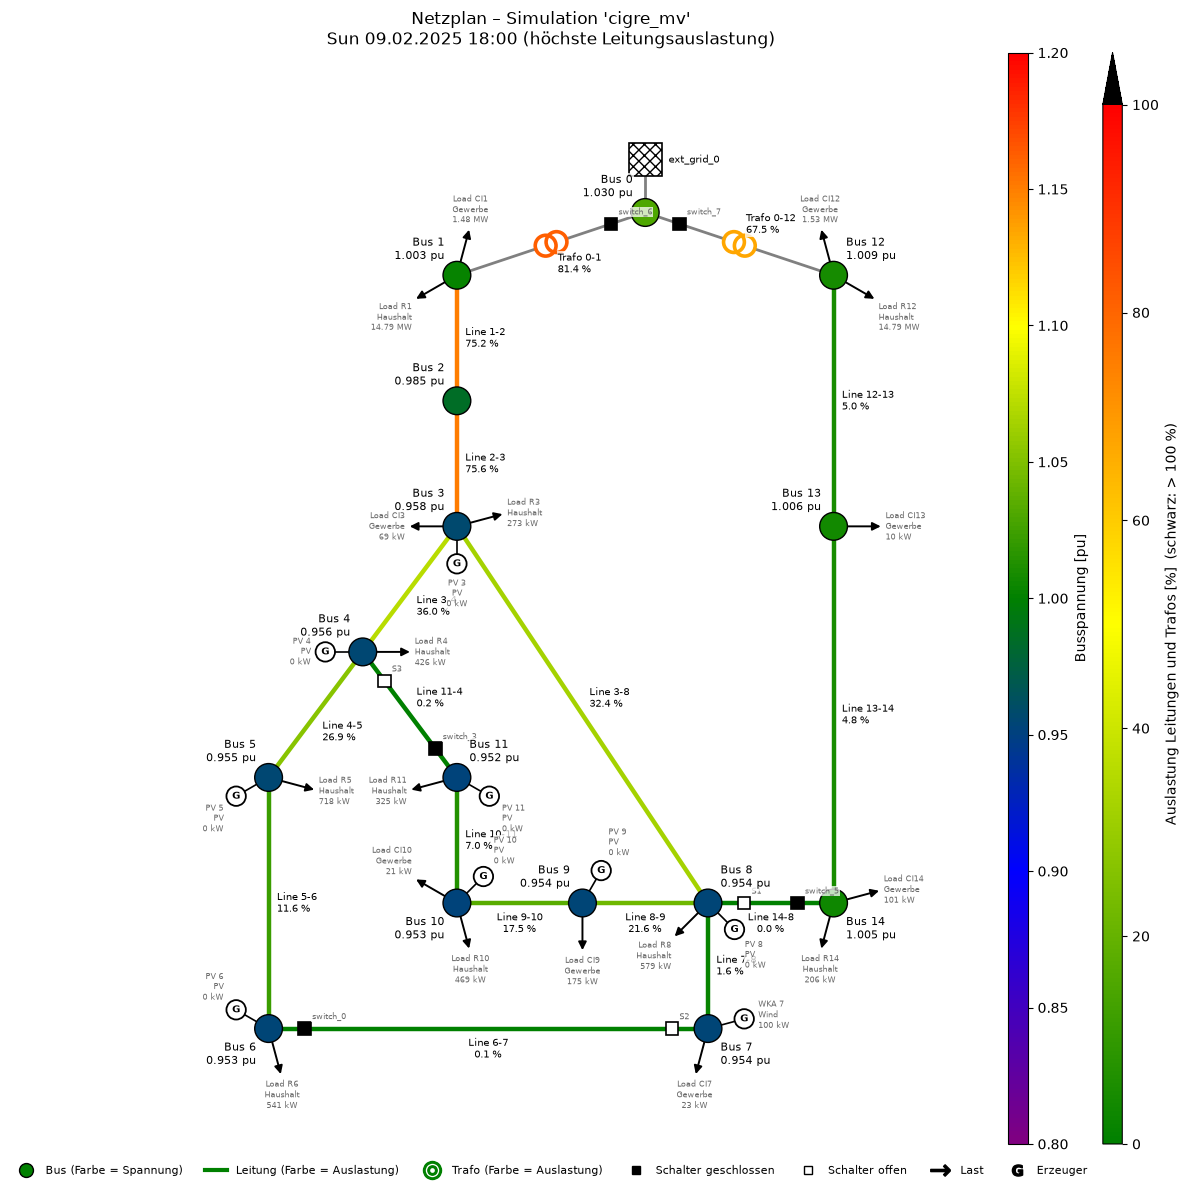

In [146]:
cigre.createDiagram(Diagram.NETWORK, time=["max_loading"])

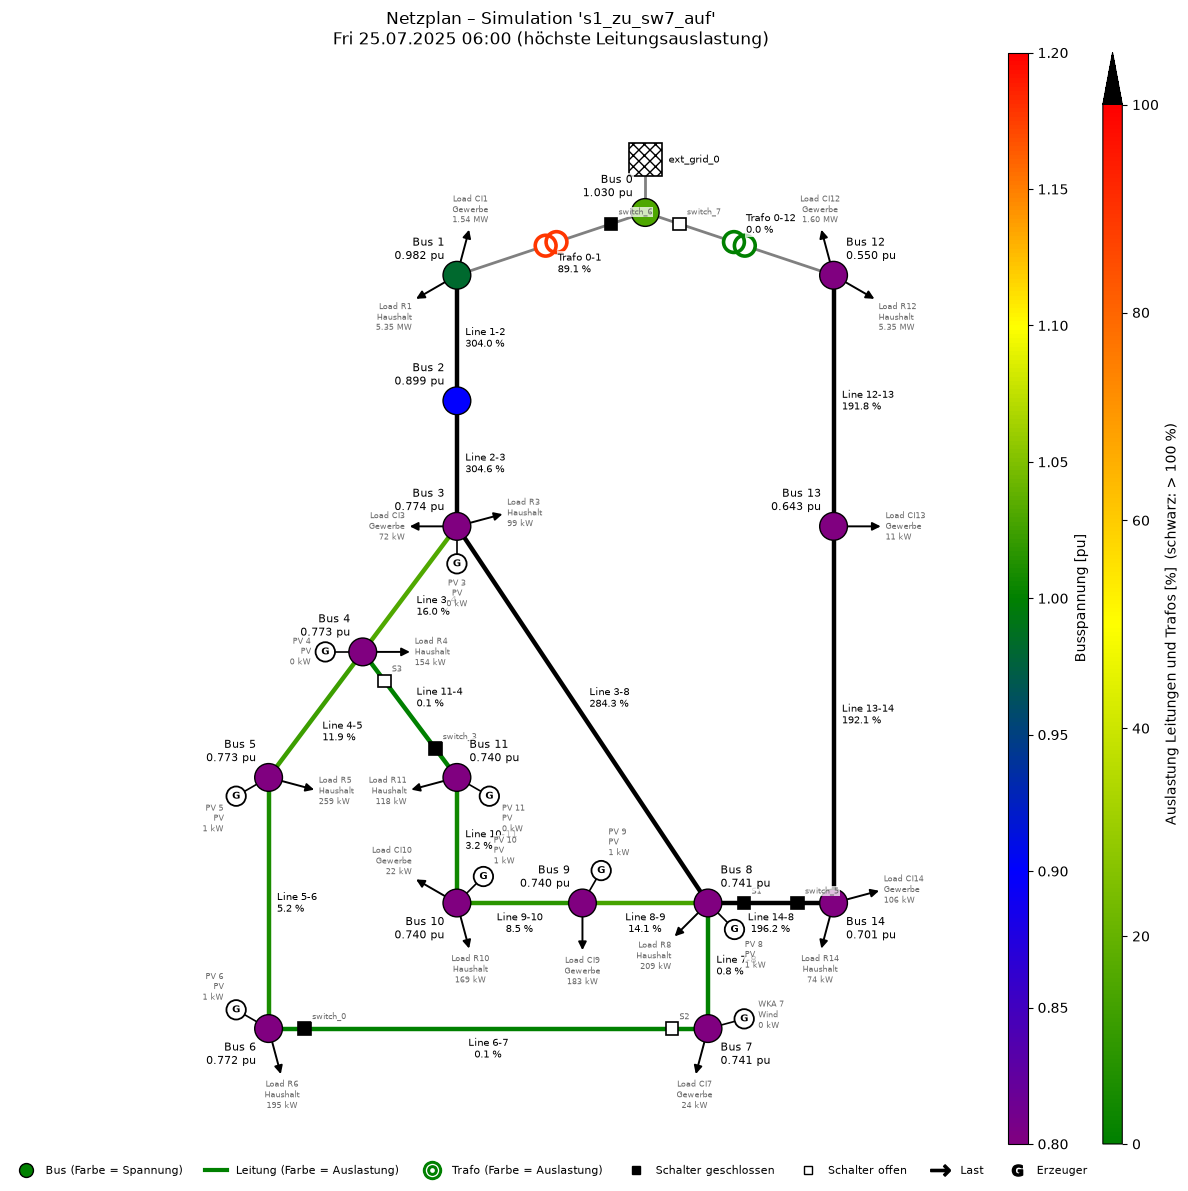

In [147]:
s1_zu_sw7_auf.createDiagram(Diagram.NETWORK, time=["max_loading"])

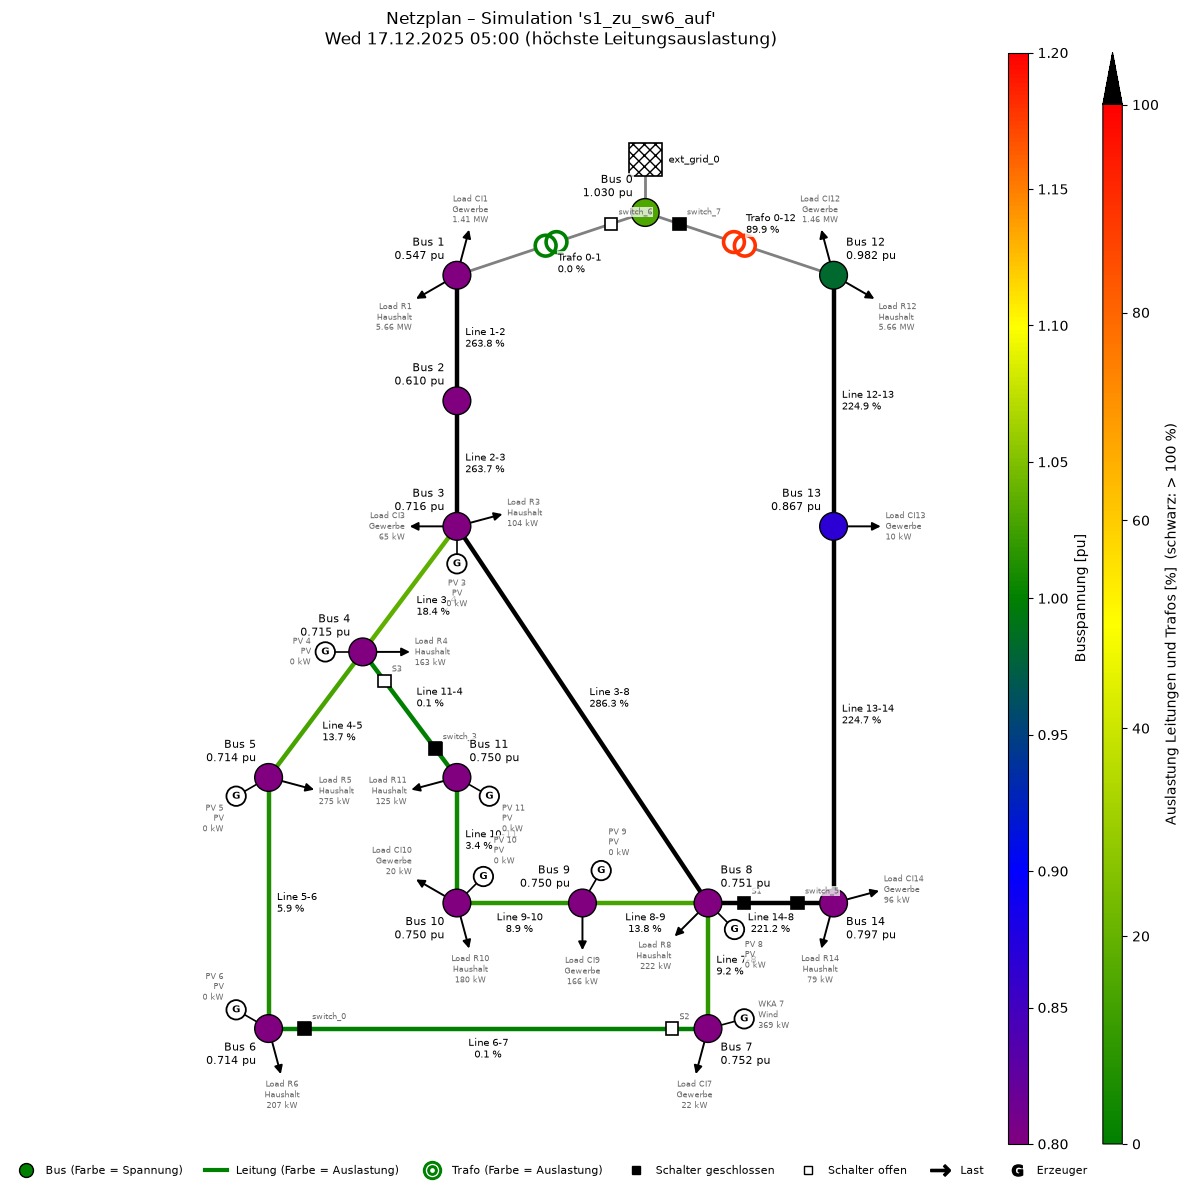

In [148]:
s1_zu_sw6_auf.createDiagram(Diagram.NETWORK, time=["max_loading"])

#### Spannung entlang des Pfades

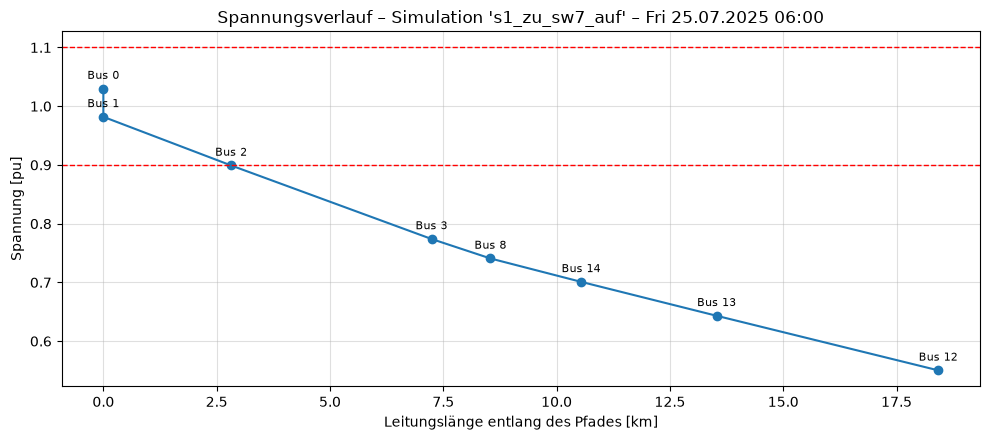

In [152]:
s1_zu_sw7_auf.createDiagram(Diagram.VOLTAGE_PROFILE, ["Bus 0", "Bus 1", "Bus 2", "Bus 3", "Bus 8", "Bus 14", "Bus 13", "Bus 12"], time="min")

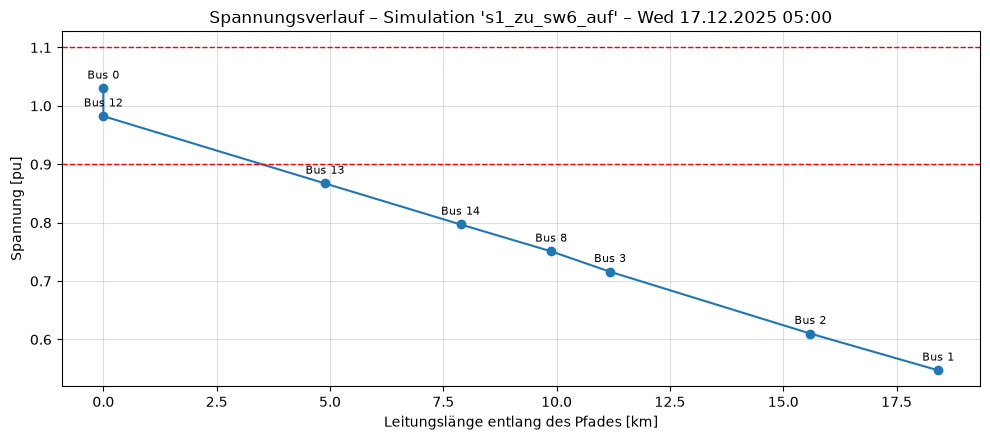

In [149]:
s1_zu_sw6_auf.createDiagram(Diagram.VOLTAGE_PROFILE, ["Bus 0", "Bus 12", "Bus 13", "Bus 14", "Bus 8", "Bus 3", "Bus 2", "Bus 1"], time="min")

#### Fazit

Die Auswertung zeigt eindeutig, das ein Trafo nicht in der Lage ist das gesamte Netzwerk aufrechtzuerhalten